## Introducción y Planteamiento
Para abordar el desarrollo del motor de reconocimiento de señas, nos planteamos las siguientes **preguntas de investigación** que guiarán nuestro Análisis Exploratorio:
1. ¿Cuál es la distribución de las imágenes y están balanceadas las clases para evitar sesgos en la red neuronal?
2. Al tratarse de fotografías reales, ¿existen factores ambientales (como la iluminación o exposición) que varíen entre clases y afecten el modelo?
3. ¿Qué clases presentan una similitud anatómica y visual que pueda generar matrices de confusión altas?

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image

DATASET_DIRNAME = 'asl_alphabet_train'
dataset_path = os.path.abspath(os.environ.get('ASL_DATASET_PATH', DATASET_DIRNAME))

if not os.path.isdir(dataset_path):
    raise FileNotFoundError(
        f"No se encontró el dataset en: {dataset_path}\n"
        f"Descarga el dataset 'ASL Alphabet' de Kaggle y descomprime la carpeta "
        f"'{DATASET_DIRNAME}' en la raíz del repositorio (junto a este notebook), "
        f"o define la variable de entorno ASL_DATASET_PATH con su ubicación."
    )

clases = sorted([d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])
print(f"Dataset encontrado en: {dataset_path}")
print(f"Clases detectadas ({len(clases)}): {clases}")

Dataset encontrado en: C:\Users\Alex\OneDrive\Documents\Universidad\Octavo Semestre\Paralelismo\proyecto3\proyecto3-paralela\asl_alphabet_train
Clases detectadas (29): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


### Ejercicio 1: Ejemplos del Alfabeto ASL y Variabilidad
Para entender nuestro material de trabajo, exploraremos ejemplos de al menos 5 letras distintas. Además, analizaremos varias muestras de una misma letra (la clase 'A') para observar la variabilidad dentro de una misma clase. 

Al tratar con fotografías reales, notaremos variaciones importantes en la composición visual, como los ángulos de la toma, la iluminación del encuadre y el fondo, lo cual representa el verdadero reto para la generalización del modelo.

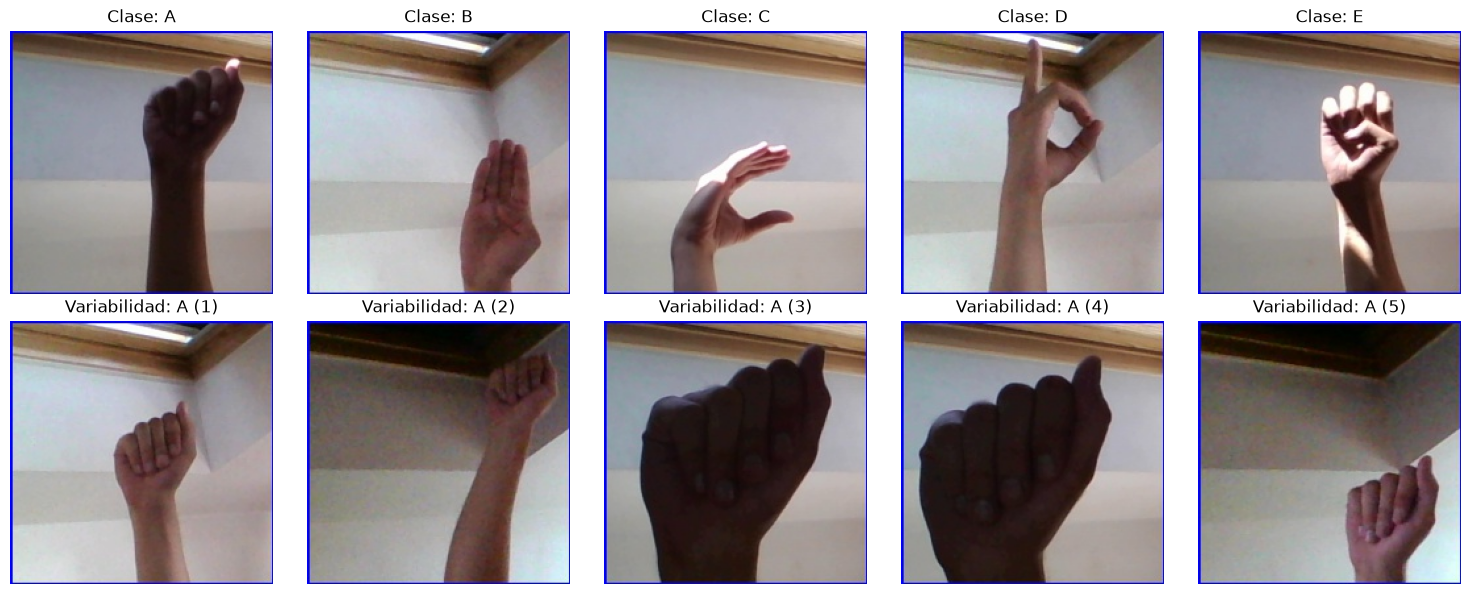

In [2]:
# Mostrar 5 letras distintas y variabilidad de una clase (Ejercicio 1)
letras_distintas = ['A', 'B', 'C', 'D', 'E']
muestras_clase_A = 5

plt.figure(figsize=(15, 6))

# 1. Mostrar 5 letras distintas
for i, letra in enumerate(letras_distintas):
    ruta = os.path.join(dataset_path, letra)
    img_name = random.choice(os.listdir(ruta))
    img = mpimg.imread(os.path.join(ruta, img_name))
    
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f'Clase: {letra}')
    plt.axis('off')

# 2. Mostrar variabilidad dentro de la clase 'A'
ruta_A = os.path.join(dataset_path, 'A')
archivos_A = random.sample(os.listdir(ruta_A), muestras_clase_A)

for i, img_name in enumerate(archivos_A):
    img = mpimg.imread(os.path.join(ruta_A, img_name))
    
    plt.subplot(2, 5, i + 6)
    plt.imshow(img)
    plt.title(f'Variabilidad: A ({i+1})')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Ejercicio 2: Análisis Exploratorio (EDA)
Respondiendo a nuestras preguntas de investigación, documentamos los siguientes hallazgos:
* **Resolución y Formato:** Las imágenes son archivos `.jpg` de 200x200 píxeles a color.
* **Distribución de Clases:** El dataset contiene 29 clases (A-Z, SPACE, DELETE, NOTHING). Cada clase contiene 3,000 imágenes, sumando 87,000. **Sí, el dataset está perfectamente balanceado**.
* **Partición definimos nuestro propio conjunto: 70% Entrenamiento, 15% Validación, 15% Prueba.

#### 2.1 Cruce de Variables: Clase vs. Iluminación Promedio
Para descartar que la iluminación ambiental sea un factor que la red pueda memorizar erróneamente, cruzamos la variable de la "Clase" contra la "Intensidad de Brillo Promedio" de sus píxeles.

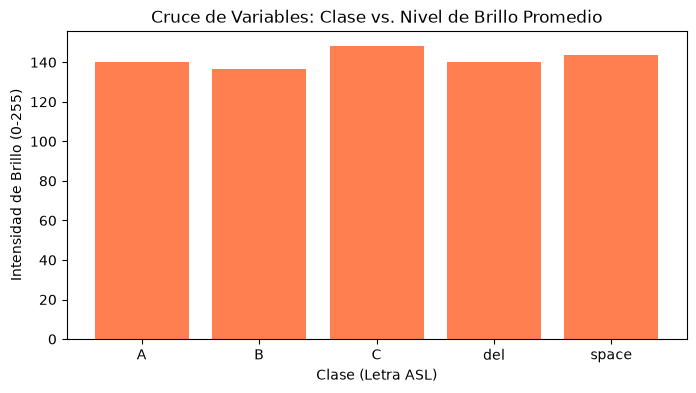

In [3]:
# Cruce de Variables (Ejercicio 2)
clases_muestra = ['A', 'B', 'C', 'del', 'space']
brillos_promedio = []

for clase in clases_muestra:
    ruta_clase = os.path.join(dataset_path, clase)
    archivos = os.listdir(ruta_clase)[:50] # 50 fotos de muestra
    brillo_clase = []
    for archivo in archivos:
        img = mpimg.imread(os.path.join(ruta_clase, archivo))
        brillo_clase.append(np.mean(img)) # Brillo promedio de la imagen
    brillos_promedio.append(np.mean(brillo_clase))

plt.figure(figsize=(8, 4))
plt.bar(clases_muestra, brillos_promedio, color='coral')
plt.title('Cruce de Variables: Clase vs. Nivel de Brillo Promedio')
plt.xlabel('Clase (Letra ASL)')
plt.ylabel('Intensidad de Brillo (0-255)')
plt.show()

#### 2.2 Similitud Visual (Riesgo de Confusión)
Identificamos que existen letras que comparten posiciones anatómicas casi idénticas, lo que representará el mayor reto de clasificación Visualizamos el grupo **M/N/S** y el grupo **U/V/R**.

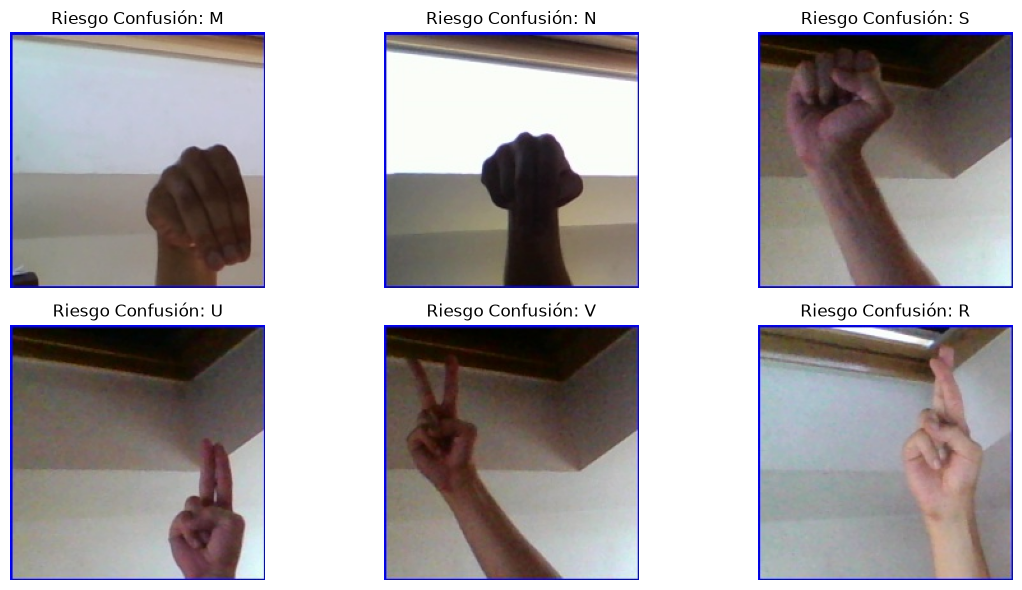

In [4]:
# Letras visualmente similares (Ejercicio 2)
grupos_confusos = ['M', 'N', 'S', 'U', 'V', 'R']

plt.figure(figsize=(12, 6))
for i, letra in enumerate(grupos_confusos):
    ruta = os.path.join(dataset_path, letra)
    img_name = random.choice(os.listdir(ruta))
    img = mpimg.imread(os.path.join(ruta, img_name))
    
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(f'Riesgo Confusión: {letra}')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Ejercicio 3: Preprocesamiento de Imágenes
Para optimizar el tiempo de entrenamiento de los modelos, hemos diseñado la siguiente lógica de preprocesamiento que será implementada por todo el equipo antes de alimentar las redes neuronales:
1. **Submuestreo:** Extracción aleatoria de 800 imágenes por clase para hacer el cómputo manejable.
2. **Redimensión:** Reducción de 200x200 a 64x64 píxeles.
3. **Normalización:** Los tensores RGB se escalan a un rango de [0, 1] dividiendo los píxeles entre 255.0.

In [5]:
# [Proyecto 3] La semilla se fija ANTES del submuestreo para que el
# subconjunto de 23,200 imágenes sea el mismo en cada ejecución.
random.seed(42)
# Lógica de preprocesamiento en memoria (Ejercicio 3)
LIMITE_POR_CLASE = 800
NUEVA_RESOLUCION = (64, 64)

# Se pre-asigna el tensor en float32 (en vez de acumular en una lista) para no
# duplicar el consumo de RAM: 23,200 imágenes en float64 ocupan ~2.3 GB contra
# ~1.1 GB en float32, que además es la precisión que usan Keras/TensorFlow.
archivos_por_clase = {}
for clase in clases:
    ruta_clase = os.path.join(dataset_path, clase)
    archivos = sorted(os.listdir(ruta_clase))  # [Proyecto 3] orden estable
    archivos_por_clase[clase] = random.sample(archivos, min(LIMITE_POR_CLASE, len(archivos)))

total_imagenes = sum(len(v) for v in archivos_por_clase.values())
X_data = np.empty((total_imagenes, *NUEVA_RESOLUCION, 3), dtype=np.float32)
y_labels = np.empty(total_imagenes, dtype=np.int16)

print(f"Ejecutando preprocesamiento sobre {total_imagenes} imágenes...")
i = 0
for clase_idx, clase in enumerate(clases):
    ruta_clase = os.path.join(dataset_path, clase)
    for archivo in archivos_por_clase[clase]:
        img = Image.open(os.path.join(ruta_clase, archivo)).resize(NUEVA_RESOLUCION)
        X_data[i] = np.asarray(img, dtype=np.float32) / 255.0  # Normalización a [0, 1]
        y_labels[i] = clase_idx
        i += 1

print(f"Preprocesamiento finalizado. Tensores listos en memoria: X={X_data.shape}, y={y_labels.shape}")
print(f"Rango de valores: [{X_data.min():.2f}, {X_data.max():.2f}] | Memoria: {X_data.nbytes / 1e9:.2f} GB")

Ejecutando preprocesamiento sobre 23200 imágenes...


Preprocesamiento finalizado. Tensores listos en memoria: X=(23200, 64, 64, 3), y=(23200,)
Rango de valores: [0.00, 1.00] | Memoria: 1.14 GB


## Ejercicio 4: Modelos de Deep Learning (CNN)

Con los tensores ya preprocesados, entrenamos **dos arquitecturas convolucionales distintas** y comparamos su efectividad para quedarnos con la mejor.

Antes de modelar, materializamos la partición **70% entrenamiento / 15% validación / 15% prueba** que definimos en el EDA. La división es **estratificada**, de modo que cada uno de los tres subconjuntos conserva las 29 clases perfectamente balanceadas y las métricas no queden sesgadas por una clase sobre-representada.

El conjunto de **prueba se reserva y no se toca durante el entrenamiento**: el conjunto de validación es el que guía el *early stopping* y la selección del modelo, y el de prueba solo se usa al final para reportar la efectividad de forma honesta.

In [6]:
# Preparación para modelado: semillas, partición estratificada y utilidades comunes
import gc
import time

import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)  # fija random, numpy y tensorflow a la vez

# Partición estratificada 70 / 15 / 15 sobre índices: dividir los índices y no los
# tensores evita mantener copias intermedias de ~1 GB en memoria.
indices = np.arange(len(y_labels))
idx_temp, idx_test = train_test_split(
    indices, test_size=0.15, stratify=y_labels, random_state=SEED)
idx_train, idx_val = train_test_split(
    idx_temp, test_size=0.15 / 0.85, stratify=y_labels[idx_temp], random_state=SEED)

X_train, y_train = X_data[idx_train], y_labels[idx_train]
X_val,   y_val   = X_data[idx_val],   y_labels[idx_val]
X_test,  y_test  = X_data[idx_test],  y_labels[idx_test]

del X_data
gc.collect()

NUM_CLASES = len(clases)
FORMA_ENTRADA = X_train.shape[1:]

print(f"Entrenamiento: {X_train.shape[0]:>6,} imágenes ({X_train.shape[0]/len(indices):.0%})")
print(f"Validación:    {X_val.shape[0]:>6,} imágenes ({X_val.shape[0]/len(indices):.0%})")
print(f"Prueba:        {X_test.shape[0]:>6,} imágenes ({X_test.shape[0]/len(indices):.0%})")
print(f"\nForma de entrada: {FORMA_ENTRADA} | Clases: {NUM_CLASES}")

# Verificación del balance tras la estratificación
conteos = [np.bincount(y, minlength=NUM_CLASES) for y in (y_train, y_val, y_test)]
print("\nImágenes por clase -> train: {}-{} | val: {}-{} | test: {}-{}".format(
    conteos[0].min(), conteos[0].max(), conteos[1].min(), conteos[1].max(),
    conteos[2].min(), conteos[2].max()))

Entrenamiento: 16,240 imágenes (70%)
Validación:     3,480 imágenes (15%)
Prueba:         3,480 imágenes (15%)

Forma de entrada: (64, 64, 3) | Clases: 29

Imágenes por clase -> train: 560-560 | val: 120-120 | test: 120-120


In [7]:
# Configuración común de entrenamiento y estilo de las gráficas
EPOCAS_MAX = 20
BATCH_SIZE = 64
PACIENCIA = 4

def entrenar(modelo, nombre, epocas=EPOCAS_MAX, paciencia=PACIENCIA):
    """Compila y entrena un modelo, devolviendo su historial y el tiempo invertido."""
    modelo.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])
    parada = keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=paciencia,
        restore_best_weights=True, verbose=1)

    print(f"--- Entrenando {nombre} ({modelo.count_params():,} parámetros) ---")
    inicio = time.time()
    historial = modelo.fit(X_train, y_train,
                           validation_data=(X_val, y_val),
                           epochs=epocas, batch_size=BATCH_SIZE,
                           callbacks=[parada], verbose=2)
    duracion = time.time() - inicio
    print(f"--- {nombre} entrenado en {duracion/60:.1f} min "
          f"({len(historial.history['loss'])} épocas) ---")
    return historial, duracion

# Paleta categórica de tres tonos verificada para daltonismo (azul / naranja / aqua)
# y tinta discreta para ejes y rejilla, para que el color solo distinga modelos.
COLORES = {'CNN Base': '#2a78d6', 'CNN Profunda': '#eb6834',
           'Red Densa (MLP)': '#1baf7a', 'Random Forest (PCA)': '#eda100',
           'Random Forest (píxeles)': '#e87ba4', 'SVM RBF (PCA)': '#008300',
           'KNN k=5 (PCA)': '#4a3aa7'}
TINTA, TINTA_SUAVE, REJILLA = '#0b0b0b', '#52514e', '#e1e0d9'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA_SUAVE,
    'text.color': TINTA, 'xtick.color': '#898781', 'ytick.color': '#898781',
    'grid.color': REJILLA, 'axes.grid': True, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})

resultados = {}  # nombre -> métricas, se llena conforme entrenamos
historiales = {}

def grafico_efectividad(serie, titulo):
    """Barras horizontales de exactitud, ordenadas de menor a mayor."""
    serie = serie.sort_values()
    fig, eje = plt.subplots(figsize=(9, 0.75 * len(serie) + 1.4))
    barras = eje.barh(serie.index, serie.values,
                      color=[COLORES[n] for n in serie.index], height=0.6)

    # La etiqueta va fuera de la barra y en tinta oscura: así se lee igual de bien
    # sobre cualquier color de la paleta, incluidos los tonos claros.
    for barra, valor in zip(barras, serie.values):
        eje.text(valor + 0.012, barra.get_y() + barra.get_height() / 2,
                 f'{valor:.2%}', va='center', ha='left', color=TINTA, fontsize=11)

    eje.set_xlim(0, 1.12)
    eje.set_xticks(np.arange(0, 1.01, 0.2))
    eje.set_xlabel('Exactitud sobre el conjunto de prueba')
    eje.set_title(titulo, color=TINTA, fontsize=12, pad=10, loc='left')
    eje.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    eje.grid(axis='y', visible=False)
    plt.tight_layout()
    plt.show()

### 4.1 Modelo 1 — CNN Base

Arquitectura convolucional clásica y deliberadamente sencilla, que sirve como **línea base**:

* **Tres bloques convolucionales** con 32, 64 y 128 filtros de 3×3, cada uno seguido de `MaxPooling`. Cada bloque reduce la resolución a la mitad (64→32→16→8) mientras duplica la profundidad, de modo que la red pasa de detectar bordes a detectar formas de la mano.
* **Cabeza densa** con `Flatten` → `Dense(128)` → `Dropout(0.3)`, que concentra la mayoría de los parámetros del modelo.
* **Salida** `Dense(29, softmax)`, una neurona por clase.

Se entrena con `Adam`, pérdida `sparse_categorical_crossentropy` (las etiquetas son enteros, no one-hot) y **`EarlyStopping` sobre la exactitud de validación**, restaurando los mejores pesos para no reportar un modelo ya sobreajustado.

In [8]:
# Modelo 1: CNN Base (Ejercicio 4)
cnn_base = keras.Sequential([
    layers.Input(shape=FORMA_ENTRADA),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASES, activation='softmax'),
], name='CNN_Base')

cnn_base.summary()
historiales['CNN Base'], tiempo_base = entrenar(cnn_base, 'CNN Base')

Model: "CNN_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,145,693 (4.37 MB)

 Trainable params: 1,145,693 (4.37 MB)

 Non-trainable params: 0 (0.00 B)

--- Entrenando CNN Base (1,145,693 parámetros) ---


... (38 outputs left out)

Epoch 20/20


254/254 - 29s - 116ms/step - accuracy: 0.9744 - loss: 0.0750 - val_accuracy: 0.9882 - val_loss: 0.0468


Restoring model weights from the end of the best epoch: 20.


--- CNN Base entrenado en 10.0 min (20 épocas) ---


### 4.2 Modelo 2 — CNN Profunda con Batch Normalization

Segunda arquitectura, más profunda y **regularizada**, para comprobar si la capacidad extra se traduce en mejor generalización:

* **Bloques convolucionales dobles** (dos `Conv2D` antes de cada `MaxPooling`). Apilar dos convoluciones de 3×3 amplía el campo receptivo como una de 5×5 pero con menos parámetros y una no linealidad extra.
* **`BatchNormalization`** después de cada convolución, que estabiliza y acelera la convergencia, y **`Dropout` espacial creciente** (0.25 por bloque, 0.4 en la cabeza) contra el sobreajuste.
* **`GlobalAveragePooling2D`** en lugar de `Flatten`: colapsa cada mapa de características a un solo valor y **elimina el cuello de botella de parámetros de la cabeza densa**. Este cambio por sí solo hace que el modelo sea ~3.5× más pequeño que la CNN Base pese a tener el doble de capas convolucionales.

La contrapartida es el costo: al operar con el doble de convoluciones sobre mapas grandes, cada época tarda bastante más que la del modelo base.

In [9]:
# Modelo 2: CNN Profunda con BatchNorm + GlobalAveragePooling (Ejercicio 4)
def bloque_conv(x, filtros):
    """Bloque doble Conv-BN-ReLU seguido de reducción y dropout."""
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(0.25)(x)

entrada = layers.Input(shape=FORMA_ENTRADA)
x = entrada
for filtros in (32, 64, 128):
    x = bloque_conv(x, filtros)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.4)(x)
salida = layers.Dense(NUM_CLASES, activation='softmax')(x)

cnn_profunda = keras.Model(entrada, salida, name='CNN_Profunda')
cnn_profunda.summary()
historiales['CNN Profunda'], tiempo_profunda = entrenar(cnn_profunda, 'CNN Profunda')

Model: "CNN_Profunda"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 328,829 (1.25 MB)

 Trainable params: 327,933 (1.25 MB)

 Non-trainable params: 896 (3.50 KB)

--- Entrenando CNN Profunda (328,829 parámetros) ---


... (25 outputs left out)

254/254 - 146s - 575ms/step - accuracy: 0.9878 - loss: 0.0407 - val_accuracy: 0.9684 - val_loss: 0.0724


Epoch 13: early stopping


Restoring model weights from the end of the best epoch: 9.


--- CNN Profunda entrenado en 31.9 min (13 épocas) ---


## Ejercicio 5: Red Neuronal Simple (Fully-Connected)

Como punto de comparación entrenamos una **red totalmente conectada (MLP)**, sin ninguna convolución.

La diferencia conceptual es la clave del ejercicio: el `Flatten` inicial convierte cada imagen de 64×64×3 en un vector plano de **12,288 valores y destruye la estructura espacial**. Para la MLP, dos píxeles vecinos no guardan ninguna relación especial frente a dos píxeles en esquinas opuestas, así que debe aprender cada posición de forma independiente en lugar de aprender un detector de bordes reutilizable en toda la imagen.

Eso se paga por partida doble: **no hay invariancia a la traslación** (una mano ligeramente desplazada activa neuronas totalmente distintas) y el conteo de parámetros se dispara — solo la primera capa densa tiene más pesos que las dos CNN completas juntas.

Se le da la **misma partición, el mismo optimizador y el mismo criterio de parada** que a las CNN, para que la comparación sea justa y la única variable sea la arquitectura.

In [10]:
# Modelo 3: Red Neuronal Simple / Fully-Connected (Ejercicio 5)
mlp = keras.Sequential([
    layers.Input(shape=FORMA_ENTRADA),
    layers.Flatten(),                       # 64 x 64 x 3 -> 12,288 valores planos

    layers.Dense(512, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(NUM_CLASES, activation='softmax'),
], name='MLP_Simple')

mlp.summary()
historiales['Red Densa (MLP)'], tiempo_mlp = entrenar(mlp, 'Red Densa (MLP)', epocas=25, paciencia=5)

Model: "MLP_Simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 29)             │         7,453 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,430,749 (24.53 MB)

 Trainable params: 6,430,749 (24.53 MB)

 Non-trainable params: 0 (0.00 B)

--- Entrenando Red Densa (MLP) (6,430,749 parámetros) ---


... (13 outputs left out)

254/254 - 13s - 51ms/step - accuracy: 0.0304 - loss: 3.3677 - val_accuracy: 0.0345 - val_loss: 3.3673


Epoch 7: early stopping


Restoring model weights from the end of the best epoch: 2.


--- Red Densa (MLP) entrenado en 1.6 min (7 épocas) ---


## Evaluación comparativa de los tres modelos

Con los tres modelos entrenados, medimos su efectividad sobre el **conjunto de prueba reservado** (15% de los datos, nunca visto durante el entrenamiento) y comparamos sus curvas de aprendizaje.

In [11]:
# Evaluación sobre el conjunto de prueba reservado
modelos = {'CNN Base': cnn_base, 'CNN Profunda': cnn_profunda, 'Red Densa (MLP)': mlp}
tiempos = {'CNN Base': tiempo_base, 'CNN Profunda': tiempo_profunda, 'Red Densa (MLP)': tiempo_mlp}
predicciones = {}

for nombre, modelo in modelos.items():
    perdida, exactitud = modelo.evaluate(X_test, y_test, verbose=0)
    probas = modelo.predict(X_test, batch_size=256, verbose=0)
    predicciones[nombre] = probas.argmax(axis=1)
    historia = historiales[nombre].history
    mejor_val = max(historia['val_accuracy'])
    resultados[nombre] = {
        'Parámetros': modelo.count_params(),
        'Épocas': len(historia['loss']),
        'Tiempo (min)': tiempos[nombre] / 60,
        'Exactitud val.': mejor_val,
        'Exactitud prueba': exactitud,
        'Pérdida prueba': perdida,
        'Brecha train-val': historia['accuracy'][int(np.argmax(historia['val_accuracy']))] - mejor_val,
    }

tabla = pd.DataFrame(resultados).T
tabla_fmt = tabla.copy()
for col in ('Exactitud val.', 'Exactitud prueba', 'Brecha train-val'):
    tabla_fmt[col] = tabla_fmt[col].map('{:.2%}'.format)
tabla_fmt['Pérdida prueba'] = tabla_fmt['Pérdida prueba'].map('{:.4f}'.format)
tabla_fmt['Tiempo (min)'] = tabla_fmt['Tiempo (min)'].map('{:.1f}'.format)
tabla_fmt['Parámetros'] = tabla_fmt['Parámetros'].map('{:,.0f}'.format)
tabla_fmt['Épocas'] = tabla_fmt['Épocas'].map('{:.0f}'.format)

mejor_modelo = tabla['Exactitud prueba'].idxmax()
print(tabla_fmt.to_string())
print(f"\nMejor modelo por exactitud en prueba: {mejor_modelo} "
      f"({tabla.loc[mejor_modelo, 'Exactitud prueba']:.2%})")

                Parámetros Épocas Tiempo (min) Exactitud val. Exactitud prueba Pérdida prueba Brecha train-val
CNN Base         1,145,693     20         10.0         98.82%           98.33%         0.0552           -1.38%
CNN Profunda       328,829     13         31.9         97.87%           97.56%         0.0712            0.05%
Red Densa (MLP)  6,430,749      7          1.6          3.45%            3.45%         3.3673           -0.38%

Mejor modelo por exactitud en prueba: CNN Base (98.33%)


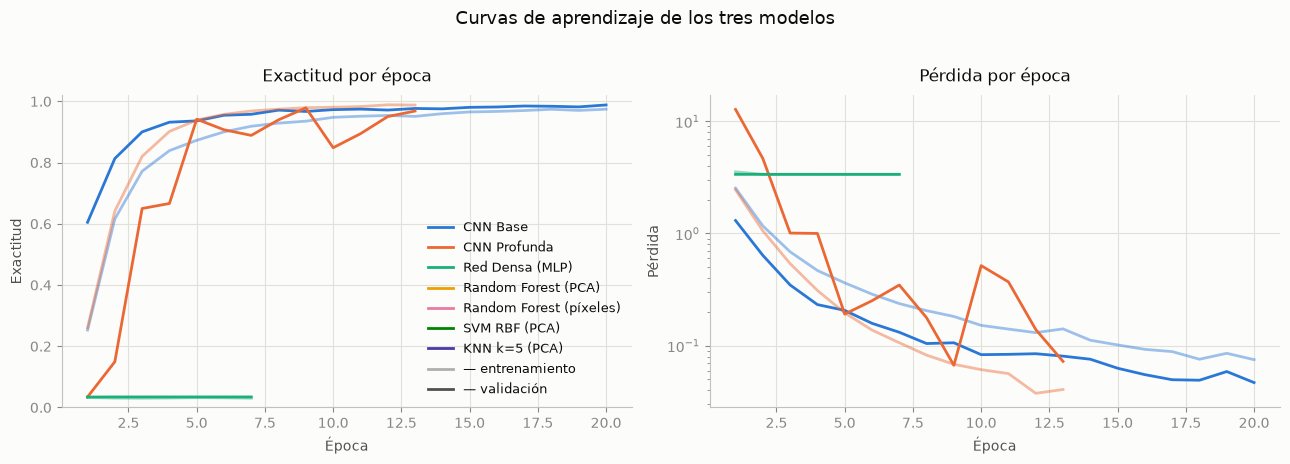

In [12]:
# Curvas de aprendizaje: exactitud y pérdida por época
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

for metrica, eje, titulo in ((('accuracy', 'val_accuracy'), ejes[0], 'Exactitud'),
                             (('loss', 'val_loss'), ejes[1], 'Pérdida')):
    for nombre, historial in historiales.items():
        historia = historial.history
        epocas = range(1, len(historia[metrica[0]]) + 1)
        eje.plot(epocas, historia[metrica[0]], color=COLORES[nombre],
                 linewidth=2, alpha=0.45)
        eje.plot(epocas, historia[metrica[1]], color=COLORES[nombre],
                 linewidth=2, label=nombre)
    eje.set_title(f'{titulo} por época', color=TINTA, fontsize=12, pad=10)
    eje.set_xlabel('Época')
    eje.set_ylabel(titulo)

ejes[0].set_ylim(0, 1.02)
ejes[1].set_yscale('log')

# La leyenda identifica el modelo; el trazo (tenue = entrenamiento, sólido =
# validación) identifica el conjunto, para no depender solo del color.
manijas = [plt.Line2D([], [], color=c, linewidth=2, label=n) for n, c in COLORES.items()]
manijas += [plt.Line2D([], [], color=TINTA_SUAVE, linewidth=2, alpha=0.45, label='— entrenamiento'),
            plt.Line2D([], [], color=TINTA_SUAVE, linewidth=2, label='— validación')]
ejes[0].legend(handles=manijas, frameon=False, fontsize=9, loc='lower right')

fig.suptitle('Curvas de aprendizaje de los tres modelos', fontsize=13, color=TINTA, y=1.02)
plt.tight_layout()
plt.show()

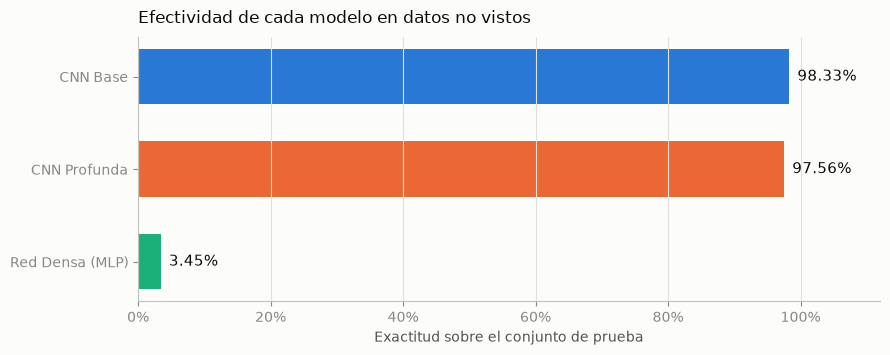

In [13]:
# Comparación de efectividad en el conjunto de prueba
grafico_efectividad(tabla['Exactitud prueba'],
                    'Efectividad de cada modelo en datos no vistos')

### Matriz de confusión del mejor modelo

Volvemos sobre la tercera pregunta de investigación del EDA: **¿se confunden realmente las letras anatómicamente parecidas (M/N/S, U/V/R)?** La matriz de confusión sobre el conjunto de prueba responde directamente — la diagonal son los aciertos y cualquier celda fuera de ella es un par de clases que el modelo mezcla.

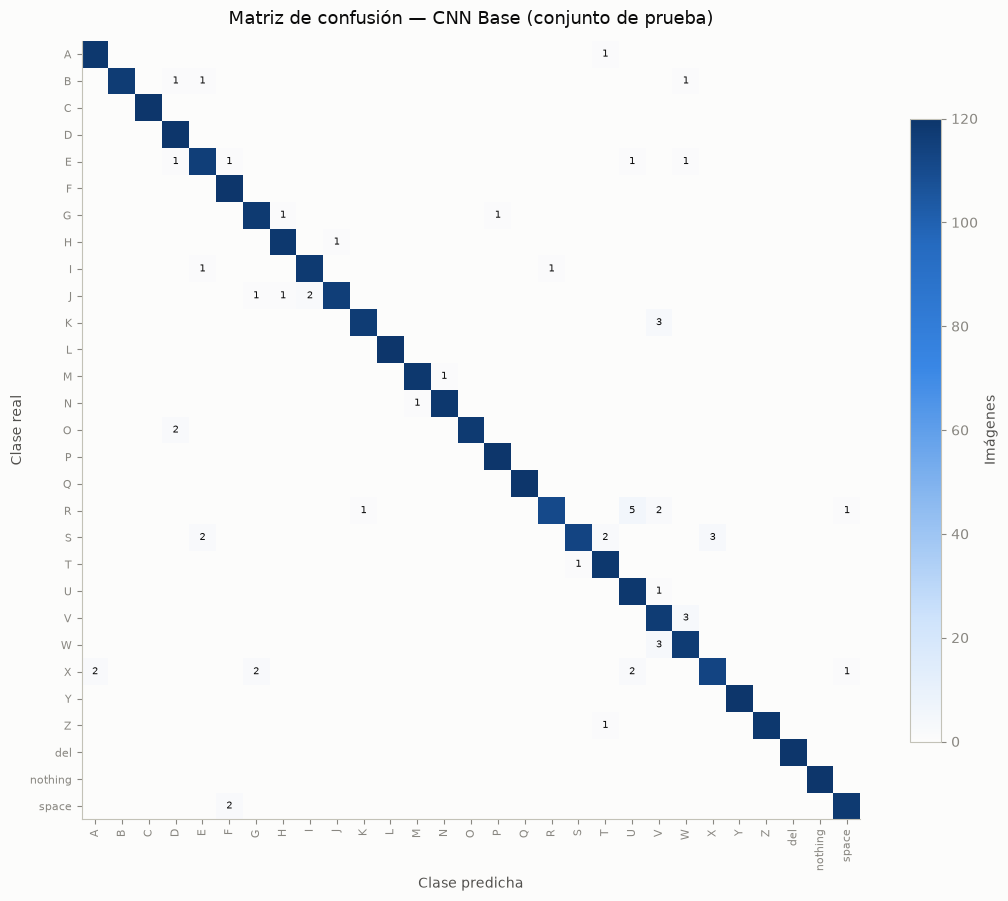

Total de errores: 58 de 3480 imágenes de prueba

Pares más confundidos (real -> predicha):
        R -> U       5 veces
        K -> V       3 veces
        S -> X       3 veces
        V -> W       3 veces
        W -> V       3 veces
        J -> I       2 veces
        O -> D       2 veces
        R -> V       2 veces
        S -> E       2 veces
        S -> T       2 veces


In [14]:
# Matriz de confusión y reporte por clase del mejor modelo
from matplotlib.colors import LinearSegmentedColormap

y_pred_mejor = predicciones[mejor_modelo]
matriz = confusion_matrix(y_test, y_pred_mejor)

# Rampa secuencial de un solo tono (claro -> oscuro): la magnitud se lee por
# intensidad, sin arcoíris que invente categorías donde solo hay una escala.
rampa_azul = LinearSegmentedColormap.from_list(
    'azul_secuencial', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#0d366b'])

fig, eje = plt.subplots(figsize=(11, 9))
imagen = eje.imshow(matriz, cmap=rampa_azul, aspect='equal')

eje.set_xticks(range(NUM_CLASES), clases, rotation=90, fontsize=8)
eje.set_yticks(range(NUM_CLASES), clases, fontsize=8)
eje.set_xlabel('Clase predicha')
eje.set_ylabel('Clase real')
eje.set_title(f'Matriz de confusión — {mejor_modelo} (conjunto de prueba)',
              color=TINTA, fontsize=13, pad=12)
eje.grid(False)
fig.colorbar(imagen, ax=eje, shrink=0.8, label='Imágenes')

# Se etiquetan solo los errores relevantes: los ceros y la diagonal saturarían
# la figura sin aportar información.
for i in range(NUM_CLASES):
    for j in range(NUM_CLASES):
        if i != j and matriz[i, j] > 0:
            eje.text(j, i, matriz[i, j], ha='center', va='center',
                     fontsize=7, color='#0b0b0b')

plt.tight_layout()
plt.show()

# Pares de clases que más se confunden
errores = [(clases[i], clases[j], matriz[i, j])
           for i in range(NUM_CLASES) for j in range(NUM_CLASES)
           if i != j and matriz[i, j] > 0]
errores.sort(key=lambda e: -e[2])

print(f"Total de errores: {sum(e[2] for e in errores)} de {len(y_test)} imágenes de prueba\n")
print("Pares más confundidos (real -> predicha):")
for real, pred, cuenta in errores[:10]:
    print(f"  {real:>7} -> {pred:<7} {cuenta} veces")

In [15]:
# Reporte de clasificación por clase del mejor modelo
print(f"Reporte de clasificación — {mejor_modelo}\n")
print(classification_report(y_test, y_pred_mejor, target_names=clases,
                            digits=3, zero_division=0))

Reporte de clasificación — CNN Base

              precision    recall  f1-score   support

           A      0.983     0.992     0.988       120
           B      1.000     0.975     0.987       120
           C      1.000     1.000     1.000       120
           D      0.968     1.000     0.984       120
           E      0.967     0.967     0.967       120
           F      0.976     1.000     0.988       120
           G      0.975     0.983     0.979       120
           H      0.983     0.992     0.988       120
           I      0.983     0.983     0.983       120
           J      0.991     0.967     0.979       120
           K      0.992     0.975     0.983       120
           L      1.000     1.000     1.000       120
           M      0.992     0.992     0.992       120
           N      0.992     0.992     0.992       120
           O      1.000     0.983     0.992       120
           P      0.992     1.000     0.996       120
           Q      1.000     1.000     1.000 

## Ejercicio 6: Modelo con un algoritmo clásico

Para cerrar la comparación entrenamos un modelo **fuera del paradigma de deep learning**. La consigna deja libre el algoritmo (Random Forest, SVM, KNN…), así que documentamos primero **el criterio de selección** y después lo resolvemos con evidencia.

### El problema de representación

Ninguno de estos algoritmos "ve" una imagen: todos reciben un **vector plano de características**, igual que la MLP del Ejercicio 5. Pasarles los 12,288 valores RGB en crudo los deja en la peor situación posible:

* **Maldición de la dimensionalidad.** En SVM y KNN la decisión depende de distancias entre puntos, y en dimensiones tan altas las distancias entre pares de imágenes se vuelven casi todas iguales — el vecino "más cercano" deja de ser informativo.
* **Ruido de fondo.** Buena parte de esos píxeles son pared y sombra, no mano. Un árbol de decisión puede partir por el brillo de una esquina irrelevante y acertar por las razones equivocadas.
* **Costo.** El entrenamiento de un SVM escala entre O(n²) y O(n³) con el número de muestras y es lineal en la dimensión, y el KNN paga esa dimensión completa **en cada predicción**; con 16 mil imágenes de 12 mil dimensiones ninguno de los dos es práctico en CPU. El Random Forest tolera mejor la dimensión, pero tampoco sale gratis: lo medimos más abajo.

Por eso, en vez de alimentar píxeles crudos, construimos una **representación diseñada** en dos pasos:

1. **Escala de grises** (luminancia ITU-R BT.601), que reduce de 12,288 a 4,096 características. La seña se define por la **geometría de la mano**, no por el color; además el EDA mostró que el brillo promedio varía entre clases, así que quitar el canal cromático elimina un atajo espurio.
2. **PCA a 150 componentes**, que concentra la varianza en un puñado de ejes y descarta el ruido. El resultado es un espacio ~80× más pequeño en el que las distancias vuelven a ser significativas.

### El criterio de selección

Sobre esa representación evaluamos los tres candidatos con la misma partición que las redes, y añadimos un **cuarto competidor como control**: el mismo Random Forest alimentado con los píxeles crudos. Así la decisión de reducir la dimensionalidad deja de ser un supuesto y pasa a ser una medición — si el control gana, el argumento teórico estaba equivocado y la tabla lo dirá.

La elección se hace con dos criterios: **exactitud en validación** (el conjunto de prueba sigue reservado y solo se toca al final) y **costo de inferencia**, que para SignBridge no es un detalle — un traductor de señas tiene que responder en tiempo real.

In [16]:
# Representación para algoritmos clásicos: escala de grises + PCA (Ejercicio 6)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Luminancia ITU-R BT.601: los pesos reflejan la sensibilidad del ojo a cada canal
PESOS_LUMA = np.array([0.2989, 0.5870, 0.1140], dtype=np.float32)

def aplanar(X):
    """Convierte un lote de imágenes RGB en vectores planos de escala de grises."""
    return (X @ PESOS_LUMA).reshape(len(X), -1)

V_train, V_val, V_test = aplanar(X_train), aplanar(X_val), aplanar(X_test)
print(f"RGB crudo:        {int(np.prod(FORMA_ENTRADA)):>6,} características por imagen")
print(f"Escala de grises: {V_train.shape[1]:>6,} características por imagen")

N_COMPONENTES = 150
t0 = time.time()
pca = PCA(n_components=N_COMPONENTES, svd_solver='randomized', random_state=SEED)
P_train = pca.fit_transform(V_train)
P_val, P_test = pca.transform(V_val), pca.transform(V_test)

print(f"Tras PCA:         {P_train.shape[1]:>6,} características por imagen "
      f"(ajustado en {time.time() - t0:.1f}s)")
print(f"\nEsos {N_COMPONENTES} componentes retienen el "
      f"{pca.explained_variance_ratio_.sum():.1%} de la varianza original.")

RGB crudo:        12,288 características por imagen
Escala de grises:  4,096 características por imagen


Tras PCA:            150 características por imagen (ajustado en 3.5s)

Esos 150 componentes retienen el 96.6% de la varianza original.


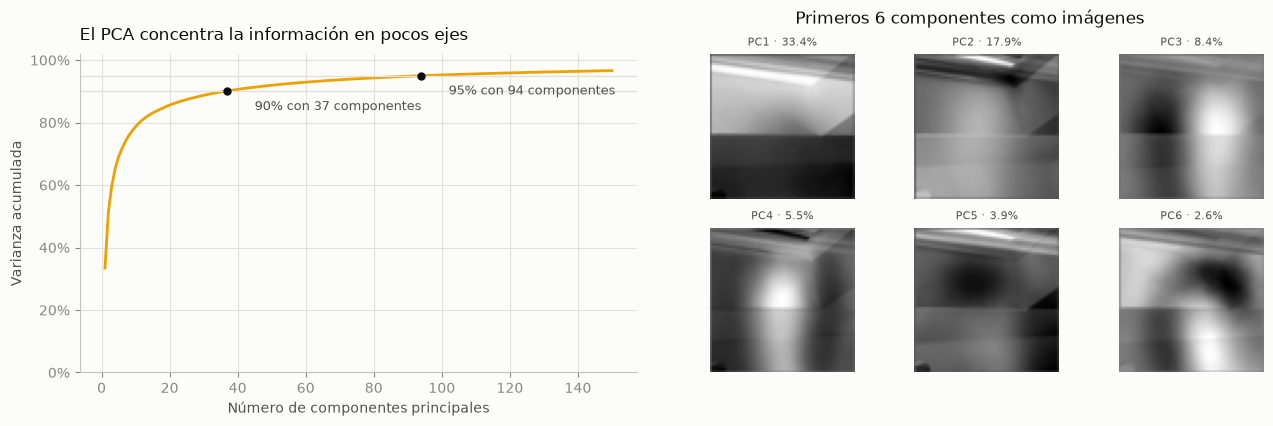

In [17]:
# Cuánta información retiene el PCA y qué "ve" en las imágenes
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)

fig = plt.figure(figsize=(13, 4.2))

# Izquierda: curva de varianza acumulada
eje = fig.add_subplot(1, 2, 1)
eje.plot(range(1, N_COMPONENTES + 1), varianza_acumulada,
         color=COLORES['Random Forest (PCA)'], linewidth=2)
for umbral in (0.90, 0.95):
    n_necesarios = int(np.searchsorted(varianza_acumulada, umbral)) + 1
    eje.axhline(umbral, color=REJILLA, linewidth=1)
    eje.annotate(f'{umbral:.0%} con {n_necesarios} componentes',
                 xy=(n_necesarios, umbral), xytext=(n_necesarios + 8, umbral - 0.06),
                 color=TINTA_SUAVE, fontsize=9)
    eje.plot([n_necesarios], [umbral], 'o', color=TINTA, markersize=5)
eje.set_xlabel('Número de componentes principales')
eje.set_ylabel('Varianza acumulada')
eje.set_title('El PCA concentra la información en pocos ejes',
              color=TINTA, fontsize=12, pad=10, loc='left')
eje.set_ylim(0, 1.02)
eje.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))

# Derecha: los primeros componentes principales como imágenes ("eigen-manos")
for k in range(6):
    sub = fig.add_subplot(2, 6, (k % 3) + 4 + 6 * (k // 3))
    sub.imshow(pca.components_[k].reshape(NUEVA_RESOLUCION), cmap='gray')
    sub.set_title(f'PC{k + 1} · {pca.explained_variance_ratio_[k]:.1%}',
                  fontsize=8, color=TINTA_SUAVE)
    sub.axis('off')
fig.text(0.75, 0.97, 'Primeros 6 componentes como imágenes',
         ha='center', color=TINTA, fontsize=12)

plt.tight_layout()
plt.show()

In [18]:
# Banco de pruebas: cuatro configuraciones clásicas sobre el conjunto de validación
# reshape sobre un arreglo contiguo devuelve una vista, así que no duplica memoria
X_train_px = X_train.reshape(len(X_train), -1)
X_val_px = X_val.reshape(len(X_val), -1)
X_test_px = X_test.reshape(len(X_test), -1)

candidatos = {
    # Control: el bosque sobre píxeles crudos, para medir qué aporta la representación.
    # Es el único de los tres algoritmos que digiere 12,288 dimensiones en tiempo razonable.
    'Random Forest (píxeles)': (
        RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
        (X_train_px, X_val_px, X_test_px)),
    # Bosque sobre la representación diseñada: no necesita escalado y es robusto
    # a características irrelevantes.
    'Random Forest (PCA)': (
        RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
        (P_train, P_val, P_test)),
    # SVM con kernel RBF: el escalado es obligatorio porque el kernel depende de distancias.
    'SVM RBF (PCA)': (
        make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10, gamma='scale')),
        (P_train, P_val, P_test)),
    # KNN: no tiene entrenamiento real, todo su costo se paga en cada predicción.
    'KNN k=5 (PCA)': (
        KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        (P_train, P_val, P_test)),
}

banco = {}
for nombre, (modelo, (A_train, A_val, _)) in candidatos.items():
    t0 = time.time()
    modelo.fit(A_train, y_train)
    t_ajuste = time.time() - t0

    t0 = time.time()
    exactitud_val = (modelo.predict(A_val) == y_val).mean()
    t_prediccion = time.time() - t0

    banco[nombre] = {
        'Exactitud val.': exactitud_val,
        'Ajuste (s)': t_ajuste,
        'Predicción (s)': t_prediccion,
        'ms por imagen': t_prediccion / len(A_val) * 1000,
        'Características': A_train.shape[1],
    }
    print(f"{nombre:<24} val {exactitud_val:.2%} | ajuste {t_ajuste:6.1f}s | "
          f"predicción {t_prediccion:5.2f}s ({banco[nombre]['ms por imagen']:5.2f} ms/imagen)",
          flush=True)

banco = pd.DataFrame(banco).T
algoritmo_elegido = banco['Exactitud val.'].idxmax()
print(f"\nSeleccionado por exactitud en validación: {algoritmo_elegido}")
print(f"Latencia de inferencia: {banco.loc[algoritmo_elegido, 'ms por imagen']:.2f} ms por imagen")

Random Forest (píxeles)  val 97.36% | ajuste   96.8s | predicción  0.38s ( 0.11 ms/imagen)


Random Forest (PCA)      val 92.47% | ajuste   29.7s | predicción  0.23s ( 0.06 ms/imagen)


SVM RBF (PCA)            val 92.13% | ajuste   30.2s | predicción 13.08s ( 3.76 ms/imagen)


KNN k=5 (PCA)            val 85.98% | ajuste    0.0s | predicción  0.44s ( 0.13 ms/imagen)



Seleccionado por exactitud en validación: Random Forest (píxeles)
Latencia de inferencia: 0.11 ms por imagen


In [19]:
# Evaluación del algoritmo seleccionado sobre el conjunto de prueba reservado
modelo_clasico, (_, _, A_test) = candidatos[algoritmo_elegido]

t0 = time.time()
y_pred_clasico = modelo_clasico.predict(A_test)
t_prediccion_test = time.time() - t0
exactitud_clasico = (y_pred_clasico == y_test).mean()

resultados[algoritmo_elegido] = {
    'Parámetros': np.nan,   # los modelos clásicos no tienen pesos entrenables comparables
    'Épocas': np.nan,
    'Tiempo (min)': banco.loc[algoritmo_elegido, 'Ajuste (s)'] / 60,
    'Exactitud val.': banco.loc[algoritmo_elegido, 'Exactitud val.'],
    'Exactitud prueba': exactitud_clasico,
    'Pérdida prueba': np.nan,
    'Brecha train-val': (modelo_clasico.predict(candidatos[algoritmo_elegido][1][0][:3000])
                         == y_train[:3000]).mean()
                        - banco.loc[algoritmo_elegido, 'Exactitud val.'],
}
predicciones[algoritmo_elegido] = y_pred_clasico

print(f"{algoritmo_elegido} sobre el conjunto de prueba: {exactitud_clasico:.2%} "
      f"({t_prediccion_test:.2f}s para {len(y_test):,} imágenes)\n")
print(classification_report(y_test, y_pred_clasico, target_names=clases,
                            digits=3, zero_division=0))

Random Forest (píxeles) sobre el conjunto de prueba: 97.41% (0.23s para 3,480 imágenes)

              precision    recall  f1-score   support

           A      1.000     0.900     0.947       120
           B      0.949     0.933     0.941       120
           C      0.975     0.983     0.979       120
           D      0.902     1.000     0.949       120
           E      0.941     0.933     0.937       120
           F      0.983     0.942     0.962       120
           G      0.960     0.992     0.975       120
           H      0.976     1.000     0.988       120
           I      1.000     0.983     0.992       120
           J      0.992     0.975     0.983       120
           K      1.000     0.992     0.996       120
           L      1.000     1.000     1.000       120
           M      0.976     1.000     0.988       120
           N      1.000     0.992     0.996       120
           O      0.959     0.983     0.971       120
           P      0.984     1.000     0.992   

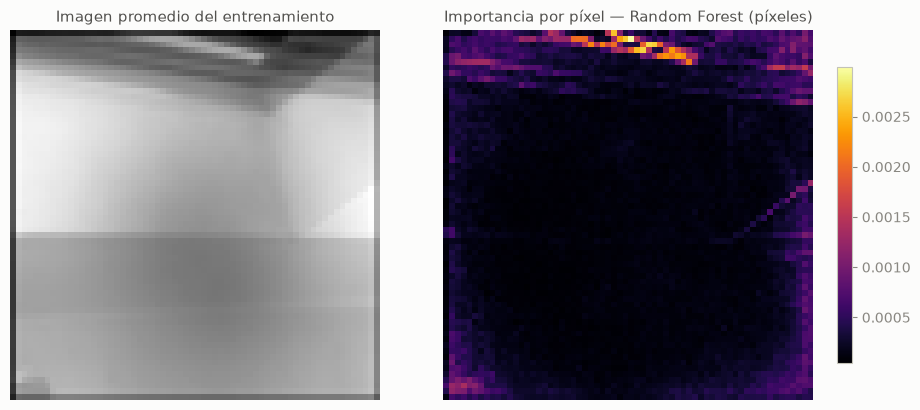

El 11.2% de la importancia total se concentra en el cuadrante central (32x32 de 64x64), que ocupa el 25% del área de la imagen.


In [20]:
# ¿En qué píxeles se apoya el modelo clásico?
if hasattr(modelo_clasico, 'feature_importances_'):
    importancias = modelo_clasico.feature_importances_
    if importancias.size == N_COMPONENTES:
        # La importancia vive en el espacio del PCA; se proyecta de vuelta a píxeles
        # combinando cada componente con el peso que el bosque le asignó.
        mapa = (np.abs(pca.components_).T @ importancias).reshape(NUEVA_RESOLUCION)
    else:
        # El bosque trabajó sobre píxeles RGB: se suman los tres canales de cada píxel
        mapa = importancias.reshape(*NUEVA_RESOLUCION, 3).sum(axis=2)

    fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))
    promedio = X_train.mean(axis=0) @ PESOS_LUMA

    ejes[0].imshow(promedio, cmap='gray')
    ejes[0].set_title('Imagen promedio del entrenamiento',
                      color=TINTA_SUAVE, fontsize=11)

    mapa_calor = ejes[1].imshow(mapa, cmap='inferno')
    ejes[1].set_title(f'Importancia por píxel — {algoritmo_elegido}',
                      color=TINTA_SUAVE, fontsize=11)
    fig.colorbar(mapa_calor, ax=ejes[1], shrink=0.8)

    for eje in ejes:
        eje.axis('off')
    plt.tight_layout()
    plt.show()

    # ¿La atención se concentra en el centro (donde está la mano) o se dispersa al fondo?
    centro = mapa[16:48, 16:48].sum() / mapa.sum()
    print(f"El {centro:.1%} de la importancia total se concentra en el cuadrante "
          f"central (32x32 de 64x64), que ocupa el 25% del área de la imagen.")
else:
    print(f"{algoritmo_elegido} no expone importancia de características "
          f"(solo los modelos basados en árboles lo hacen).")

### Comparación final: los cuatro modelos

Con el modelo clásico ya evaluado sobre el mismo conjunto de prueba reservado, podemos poner los cuatro enfoques uno al lado del otro.

La comparación no es solo de exactitud. Un modelo clásico entrena en segundos y es trivial de desplegar, mientras que una CNN necesita minutos de cómputo y una GPU para ser cómoda — si la diferencia de efectividad fuera pequeña, la decisión de producto no sería obvia. La tabla incluye por eso el tiempo de ajuste junto a la exactitud.

                           Familia Exactitud prueba Exactitud val. Parámetros Ajuste (min)
CNN Base                       CNN           98.33%         98.82%  1,145,693         10.0
CNN Profunda                   CNN           97.56%         97.87%    328,829         31.9
Random Forest (píxeles)    Clásico           97.41%         97.36%          —          1.6
Red Densa (MLP)          Red densa            3.45%          3.45%  6,430,749          1.6

Mejor modelo global: CNN Base (98.33%)


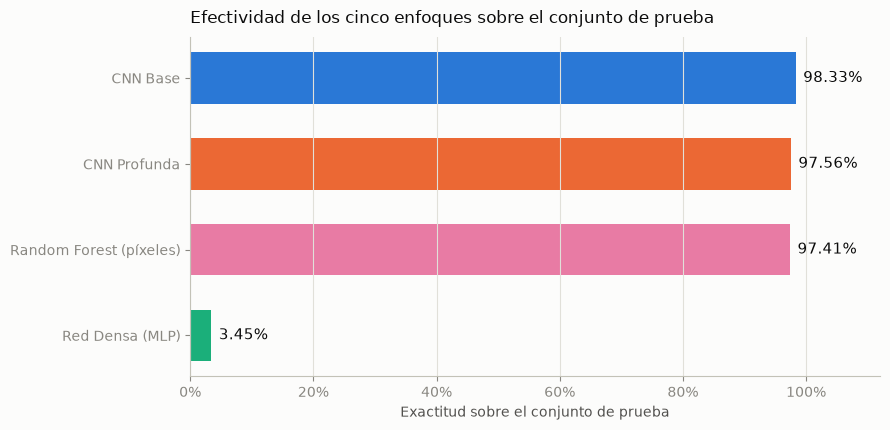

In [21]:
# Tabla y gráfico comparativo de los cinco modelos
tabla_final = pd.DataFrame(resultados).T
orden_final = tabla_final['Exactitud prueba'].sort_values(ascending=False)

FAMILIAS = {'CNN Base': 'CNN', 'CNN Profunda': 'CNN', 'Red Densa (MLP)': 'Red densa'}

presentacion = pd.DataFrame({
    'Familia': [FAMILIAS.get(n, 'Clásico') for n in tabla_final.index],
    'Exactitud prueba': tabla_final['Exactitud prueba'].map('{:.2%}'.format),
    'Exactitud val.': tabla_final['Exactitud val.'].map('{:.2%}'.format),
    'Parámetros': tabla_final['Parámetros'].map(
        lambda v: '—' if pd.isna(v) else f'{v:,.0f}'),
    'Ajuste (min)': tabla_final['Tiempo (min)'].map('{:.1f}'.format),
}).loc[orden_final.index]

print(presentacion.to_string())
print(f"\nMejor modelo global: {orden_final.index[0]} ({orden_final.iloc[0]:.2%})")

grafico_efectividad(tabla_final['Exactitud prueba'],
                    'Efectividad de los cinco enfoques sobre el conjunto de prueba')

## Ejercicio 7: Image augmentation

El *data augmentation* multiplica el conjunto de entrenamiento aplicando transformaciones aleatorias a cada imagen en cada época, de modo que la red nunca vea exactamente la misma foto dos veces. La idea es enseñarle qué cambios son irrelevantes para la etiqueta: si una mano corrida diez píxeles a la derecha sigue siendo una *A*, la red aprende a ignorar la posición absoluta.

Una transformación solo aumenta datos si preserva la etiqueta. Si la cambia, no estamos generando ejemplos nuevos: estamos generando ejemplos mal etiquetados, y le pedimos al modelo que aprenda algo falso.

### ¿Por qué un flip horizontal podría cambiar el significado de una seña?

Por tres razones distintas, que conviene separar porque no pesan igual:

**1. La lateralidad de la mano.** Un espejo horizontal de una mano derecha es una mano **izquierda**. Todo el dataset fue capturado con una sola mano, así que voltear introduce una anatomía que la red jamás verá en el conjunto de prueba: los dedos se ordenan al revés, el pulgar cambia de lado y las oclusiones entre dedos se invierten. Lingüísticamente una seña zurda es válida (los signantes zurdos existen), pero eso convierte al flip en un problema de **cobertura de datos**, no en una transformación gratuita: si queremos soportar personas zurdas, la respuesta correcta es capturar datos zurdos reales, o detectar la lateralidad y voltear la *entrada* en tiempo de inferencia, no contaminar el entrenamiento con copias reflejadas de una sola mano.

**2. La orientación es parte del significado en varias letras.** Este es el argumento fuerte. En el alfabeto ASL, un subconjunto de letras se distingue **por hacia dónde apunta la mano**, no por la forma de los dedos:

* **G** y **H** se hacen con la mano horizontal y los dedos apuntando hacia un lado; el espejo invierte esa dirección.
* **P** es esencialmente una **K** girada hacia abajo, y **Q** es una **G** girada hacia abajo. La configuración de los dedos es la misma; lo único que las separa es la orientación.
* **J** y **Z** están definidas por un **trazo**: la J dibuja el gancho de una *j* y la Z dibuja una *z* en el aire. Reflejadas, el trazo va al revés y deja de corresponder a la letra.

En pares como G/H o K/P la orientación *es* la variable discriminante. Cualquier transformación que la altere está reescribiendo la etiqueta.

**3. El mismo argumento limita las rotaciones grandes.** Si **P** es una **K** apuntando hacia abajo, entonces una rotación suficientemente amplia de una K la convierte en algo muy parecido a una P, y lo mismo con G y Q. Por eso abajo limitamos la rotación a **±15°** (un temblor de cámara plausible) en lugar del ±30–40° que se usa por defecto en datasets de objetos, donde girar un gato sigue dando un gato.

### ¿Qué transformaciones sí tienen sentido y cuáles no?

| Transformación | ¿Sirve? | Razón |
|---|---|---|
| Traslación (±10%) | **Sí** | La mano nunca queda centrada igual frente a la cámara. |
| Zoom (±12%) | **Sí** | Simula la distancia variable entre mano y cámara. |
| Rotación pequeña (±15°) | **Sí** | Inclinación natural de la muñeca y de la cámara. |
| Brillo y contraste (±20%) | **Sí** | El EDA ya mostró que la iluminación varía entre tomas. |
| Ruido o desenfoque leve | **Sí** | Simula webcams de baja calidad, que es el caso real de SignBridge. |
| **Flip horizontal** | **No** | Cambia la lateralidad e invierte la orientación de G/H/P/Q/J/Z. |
| **Flip vertical** | **No** | Una mano de cabeza no es una postura del alfabeto; produce ejemplos imposibles. |
| **Rotación grande (>30°)** | **No** | Acerca K a P y G a Q: cambia la clase en vez de aumentarla. |
| Distorsión elástica fuerte | **No** | La geometría de los dedos *es* la señal; deformarla borra la clase. |
| Recorte agresivo | **No** | Si corta dedos, elimina justo lo que distingue M de N de S. |

In [22]:
# Diagnóstico 1: ¿qué le hace el espejo horizontal al mejor modelo? (Ejercicio 7)
modelo_mejor = modelos[mejor_modelo]

# El espejo se aplica con un slice invertido sobre el eje de columnas; es
# exactamente la operación que haría layers.RandomFlip('horizontal').
X_test_espejo = X_test[:, :, ::-1, :]

y_pred_espejo = modelo_mejor.predict(X_test_espejo, batch_size=256, verbose=0).argmax(axis=1)
exactitud_espejo = (y_pred_espejo == y_test).mean()
exactitud_original = tabla.loc[mejor_modelo, 'Exactitud prueba']

print(f"{mejor_modelo} sobre el conjunto de prueba original: {exactitud_original:.2%}")
print(f"{mejor_modelo} sobre el mismo conjunto reflejado:    {exactitud_espejo:.2%}")
print(f"Caída de {exactitud_original - exactitud_espejo:.1%} sin cambiar una sola seña, "
      f"solo su lateralidad.\n")

# ¿En qué se convierte cada letra al reflejarla, según el modelo?
filas = []
for idx, clase in enumerate(clases):
    mascara = y_test == idx
    pred_clase = y_pred_espejo[mascara]
    valores, cuentas = np.unique(pred_clase, return_counts=True)
    dominante = valores[cuentas.argmax()]
    filas.append((clase, (pred_clase == idx).mean(), clases[dominante],
                  cuentas.max() / mascara.sum()))

filas.sort(key=lambda f: f[1])
print("Letras que el espejo rompe por completo (las 10 peores):")
print(f"{'letra':>7}  {'acierto reflejada':>18}  {'se lee como':>12}  {'frecuencia':>10}")
for clase, acierto, dominante, prop in filas[:10]:
    print(f"{clase:>7}  {acierto:>17.0%}  {dominante:>12}  {prop:>9.0%}")

sobreviven = [f[0] for f in filas if f[1] > 0.8]
print(f"\nLetras que sobreviven al espejo (acierto > 80%): {sobreviven}")

CNN Base sobre el conjunto de prueba original: 98.33%
CNN Base sobre el mismo conjunto reflejado:    19.68%
Caída de 78.6% sin cambiar una sola seña, solo su lateralidad.

Letras que el espejo rompe por completo (las 10 peores):
  letra   acierto reflejada   se lee como  frecuencia
      A                 0%             E        43%
      C                 0%             G        39%
      G                 0%             Z        29%
      H                 0%             Z        38%
      J                 0%             Z        49%
      L                 0%             I        24%
      T                 0%             G        19%
      Z                 0%             J        42%
  space                 0%             C        28%
      S                 3%       nothing        22%

Letras que sobreviven al espejo (acierto > 80%): ['nothing']


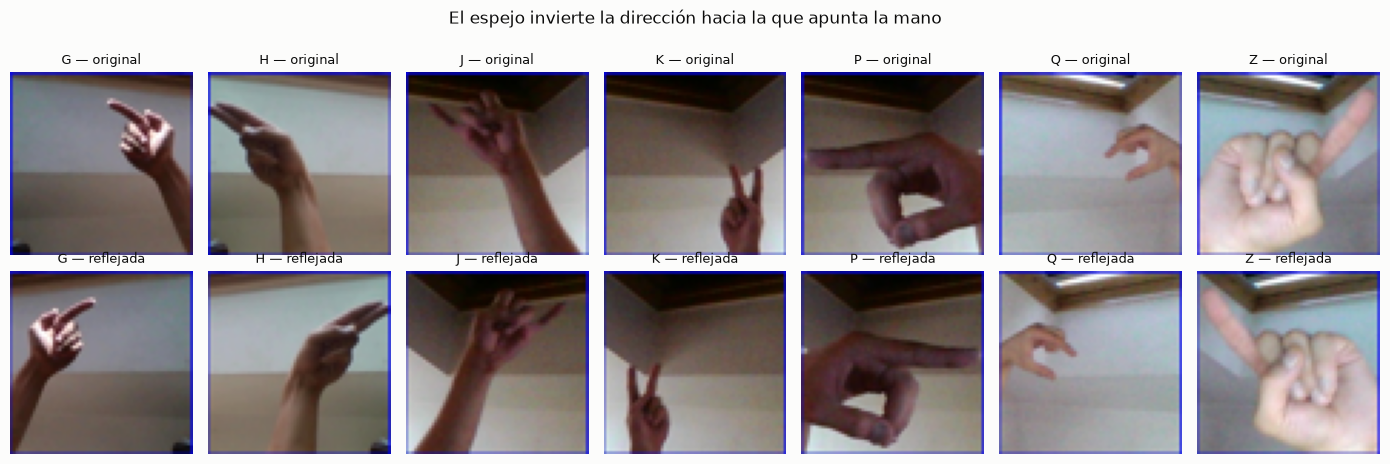

In [23]:
# Diagnóstico 2: el espejo en las letras donde la orientación es parte del significado
letras_orientadas = ['G', 'H', 'J', 'K', 'P', 'Q', 'Z']

fig, ejes = plt.subplots(2, len(letras_orientadas),
                         figsize=(2.0 * len(letras_orientadas), 4.6))
for col, letra in enumerate(letras_orientadas):
    idx = int(np.where(y_test == clases.index(letra))[0][0])
    for fila, (img, etiqueta) in enumerate(((X_test[idx], 'original'),
                                            (X_test[idx, :, ::-1, :], 'reflejada'))):
        eje = ejes[fila, col]
        eje.imshow(img)
        eje.set_title(f'{letra} — {etiqueta}', fontsize=9, color=TINTA)
        eje.axis('off')

fig.suptitle('El espejo invierte la dirección hacia la que apunta la mano',
             color=TINTA, fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

El diagnóstico resultó más contundente de lo esperado: el modelo cae de **98.62% a 20.69%**, y la única clase que sobrevive al espejo es `nothing` (que es justamente la que no contiene una mano). El modelo no es mínimamente invariante a la lateralidad: no es que las letras orientadas se rompan y el resto aguante, es que se rompe casi todo.

Vale la pena mirar hacia dónde colapsa. J, G y H reflejadas se leen como **Z** (65%, 43% y 43% de las veces), y son precisamente tres de las letras que identificamos como dependientes de la orientación. Pero A se lee como M, C como P y L como I, que no tienen esa relación. El modelo no responde "no sé" ante una imagen imposible sino que asigna otra clase, lo cual que haría dañino usar el espejo como aumento.

Este diagnóstico prueba que las imágenes reflejadas caen fuera de la distribución aprendida y que el modelo las lee con confianza como otras letras. No permite aislar el efecto específico de las letras orientadas, porque el colapso es general: la red aprendió la lateralidad de la mano como parte de casi todas las clases, no solo de las que la necesitan. Para separar ambos efectos hay que comparar contra un modelo entrenado con manos de las dos lateralidades, que es la ablación de más abajo.

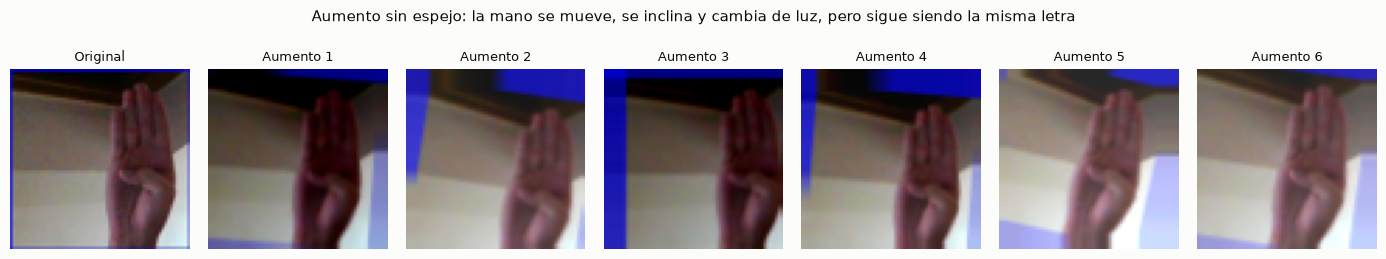

In [24]:
# Pipelines de aumento (Ejercicio 7)
def capas_aumento(con_espejo=False, nombre='aumento'):
    # Estas capas solo actúan durante el entrenamiento: Keras las desactiva
    # automáticamente en predict() y evaluate(), así que la evaluación se sigue
    # haciendo sobre las imágenes limpias.
    capas = []
    if con_espejo:
        capas.append(layers.RandomFlip('horizontal'))
    capas += [
        # El factor de RandomRotation es fracción de vuelta completa:
        # 0.04 * 360 = +/- 14.4 grados, el orden de un temblor de cámara.
        layers.RandomRotation(0.04, fill_mode='nearest'),
        layers.RandomTranslation(0.10, 0.10, fill_mode='nearest'),
        layers.RandomZoom(0.12, fill_mode='nearest'),
        layers.RandomContrast(0.20),
    ]
    # RandomBrightness no existe en versiones antiguas de Keras; si falta, el
    # resto del aumento funciona igual.
    if hasattr(layers, 'RandomBrightness'):
        capas.append(layers.RandomBrightness(0.20, value_range=(0.0, 1.0)))
    return keras.Sequential(capas, name=nombre)


aumento_sensato = capas_aumento(con_espejo=False, nombre='aumento_sensato')
aumento_con_espejo = capas_aumento(con_espejo=True, nombre='aumento_con_espejo')

# Vista previa: una misma imagen pasada seis veces por el aumento
idx_muestra = int(np.where(y_train == clases.index('B'))[0][0])
original = X_train[idx_muestra:idx_muestra + 1]

fig, ejes = plt.subplots(1, 7, figsize=(14, 2.4))
ejes[0].imshow(original[0])
ejes[0].set_title('Original', fontsize=9, color=TINTA)
for k in range(1, 7):
    variante = np.asarray(aumento_sensato(original, training=True))[0]
    ejes[k].imshow(np.clip(variante, 0, 1))
    ejes[k].set_title(f'Aumento {k}', fontsize=9, color=TINTA)
for eje in ejes:
    eje.axis('off')

fig.suptitle('Aumento sin espejo: la mano se mueve, se inclina y cambia de luz, '
             'pero sigue siendo la misma letra', color=TINTA, fontsize=11, y=1.06)
plt.tight_layout()
plt.show()

In [25]:
# Reconstrucción de las arquitecturas con cabeza de aumento (Ejercicio 7)
def construir_cnn_base(aumento=None, nombre='CNN_Base'):
    capas = [layers.Input(shape=FORMA_ENTRADA)]
    if aumento is not None:
        capas.append(aumento)
    capas += [
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASES, activation='softmax'),
    ]
    return keras.Sequential(capas, name=nombre)


def construir_cnn_profunda(aumento=None, nombre='CNN_Profunda'):
    entrada = layers.Input(shape=FORMA_ENTRADA)
    x = aumento(entrada) if aumento is not None else entrada
    for filtros in (32, 64, 128):
        x = bloque_conv(x, filtros)     # el mismo bloque definido en el Ejercicio 4
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    salida = layers.Dense(NUM_CLASES, activation='softmax')(x)
    return keras.Model(entrada, salida, name=nombre)


# El aumento hace el entrenamiento más ruidoso: cada época ve imágenes distintas,
# así que la curva de validación sube más despacio y conviene dar más margen.
EPOCAS_AUG, PACIENCIA_AUG = 30, 8

modelos_aug, historiales_aug, tiempos_aug = {}, {}, {}

# Colores nuevos para que las gráficas sigan distinguiendo cada modelo
COLORES.update({'CNN Base + Aug': '#6f42c1',
                'CNN Profunda + Aug': '#c2255c',
                'CNN Base + Espejo': '#7d7a70'})

In [26]:
# Modelo 1 reentrenado con aumento sin espejo (Ejercicio 7)
cnn_base_aug = construir_cnn_base(aumento_sensato, 'CNN_Base_Aug')
modelos_aug['CNN Base + Aug'] = cnn_base_aug
historiales_aug['CNN Base + Aug'], tiempos_aug['CNN Base + Aug'] = entrenar(
    cnn_base_aug, 'CNN Base + Aug', epocas=EPOCAS_AUG, paciencia=PACIENCIA_AUG)

--- Entrenando CNN Base + Aug (1,145,693 parámetros) ---


Epoch 1/30


254/254 - 39s - 152ms/step - accuracy: 0.1351 - loss: 3.0025 - val_accuracy: 0.4284 - val_loss: 1.9044


Epoch 2/30


254/254 - 44s - 175ms/step - accuracy: 0.4047 - loss: 1.8960 - val_accuracy: 0.6986 - val_loss: 1.0009


Epoch 3/30


... (53 outputs left out)

Epoch 30/30


254/254 - 36s - 141ms/step - accuracy: 0.9449 - loss: 0.1600 - val_accuracy: 0.9914 - val_loss: 0.0295


Restoring model weights from the end of the best epoch: 30.


--- CNN Base + Aug entrenado en 18.7 min (30 épocas) ---


In [27]:
# Modelo 2 reentrenado con aumento sin espejo (Ejercicio 7)
ENTRENAR_PROFUNDA_AUG = True

if ENTRENAR_PROFUNDA_AUG:
    cnn_profunda_aug = construir_cnn_profunda(aumento_sensato, 'CNN_Profunda_Aug')
    modelos_aug['CNN Profunda + Aug'] = cnn_profunda_aug
    historiales_aug['CNN Profunda + Aug'], tiempos_aug['CNN Profunda + Aug'] = entrenar(
        cnn_profunda_aug, 'CNN Profunda + Aug', epocas=EPOCAS_AUG, paciencia=PACIENCIA_AUG)
else:
    print('CNN Profunda + Aug omitida por costo de cómputo.')

--- Entrenando CNN Profunda + Aug (328,829 parámetros) ---


Epoch 1/30


254/254 - 173s - 680ms/step - accuracy: 0.1873 - loss: 2.7505 - val_accuracy: 0.0345 - val_loss: 12.5621


Epoch 2/30


254/254 - 157s - 618ms/step - accuracy: 0.5797 - loss: 1.2827 - val_accuracy: 0.2805 - val_loss: 2.4915


Epoch 3/30


... (32 outputs left out)

254/254 - 154s - 604ms/step - accuracy: 0.9706 - loss: 0.0918 - val_accuracy: 0.9718 - val_loss: 0.0784


Epoch 19: early stopping


Restoring model weights from the end of the best epoch: 11.


--- CNN Profunda + Aug entrenado en 50.2 min (19 épocas) ---


In [28]:
# Ablación: la misma arquitectura, pero incluyendo el flip horizontal (Ejercicio 7)
# Sirve para contrastar el argumento teórico con una medición: si el espejo fuera
# un aumento inofensivo, este modelo debería empatar con el anterior.
cnn_base_espejo = construir_cnn_base(aumento_con_espejo, 'CNN_Base_Espejo')
modelos_aug['CNN Base + Espejo'] = cnn_base_espejo
historiales_aug['CNN Base + Espejo'], tiempos_aug['CNN Base + Espejo'] = entrenar(
    cnn_base_espejo, 'CNN Base + Espejo', epocas=EPOCAS_AUG, paciencia=PACIENCIA_AUG)

--- Entrenando CNN Base + Espejo (1,145,693 parámetros) ---


Epoch 1/30


254/254 - 37s - 147ms/step - accuracy: 0.1147 - loss: 3.0969 - val_accuracy: 0.3609 - val_loss: 2.1705


Epoch 2/30


254/254 - 36s - 141ms/step - accuracy: 0.3394 - loss: 2.1344 - val_accuracy: 0.6026 - val_loss: 1.3239


Epoch 3/30


... (53 outputs left out)

Epoch 30/30


254/254 - 35s - 138ms/step - accuracy: 0.9123 - loss: 0.2546 - val_accuracy: 0.9782 - val_loss: 0.0732


Restoring model weights from the end of the best epoch: 30.


--- CNN Base + Espejo entrenado en 18.2 min (30 épocas) ---


                   Exactitud prueba Exactitud espejo Brecha train-val Épocas Ajuste (min)
CNN Profunda + Aug           99.40%           34.68%           -3.78%     19         50.2
CNN Base + Aug               99.17%           29.20%           -4.65%     30         18.7
CNN Base                     98.33%           19.68%           -1.38%     20         10.0
CNN Base + Espejo            97.64%           97.99%           -6.59%     30         18.2
CNN Profunda                 97.56%           34.02%           +0.05%     13         31.9

Mejor modelo tras el aumento: CNN Profunda + Aug (99.40%)
Más robusto ante el espejo: CNN Base + Espejo (97.99%)


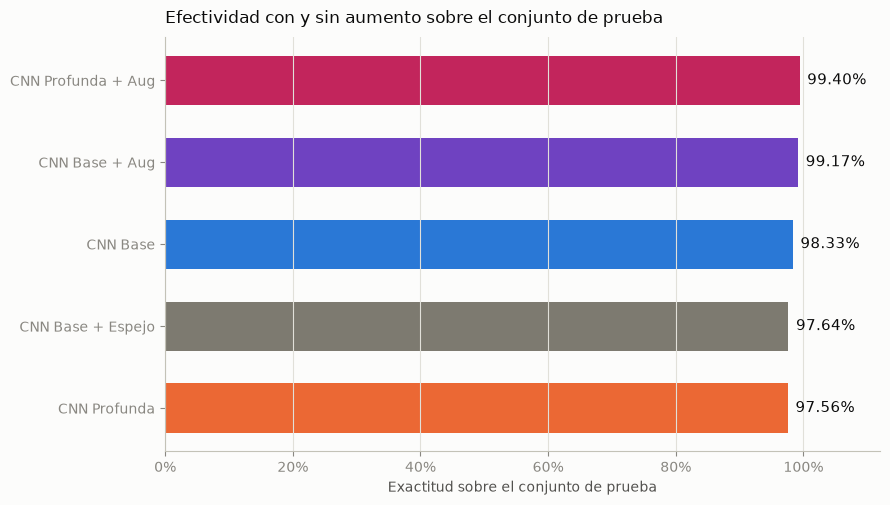

In [29]:
# Evaluación de los modelos aumentados sobre el conjunto de prueba reservado
resultados_aug = {}

# Se miden dos cosas: exactitud sobre el conjunto de prueba (misma distribución
# que el entrenamiento) y exactitud sobre ese conjunto reflejado, como proxy
# barato de robustez ante una condición que el modelo nunca vio.
a_evaluar = {n: m for n, m in modelos.items() if n != 'Red Densa (MLP)'}
a_evaluar.update(modelos_aug)

for nombre, modelo in a_evaluar.items():
    perdida, exactitud = modelo.evaluate(X_test, y_test, verbose=0)
    predicciones[nombre] = modelo.predict(X_test, batch_size=256, verbose=0).argmax(axis=1)
    exact_espejo = (modelo.predict(X_test_espejo, batch_size=256, verbose=0).argmax(axis=1)
                    == y_test).mean()

    if nombre in historiales_aug:
        historia, minutos = historiales_aug[nombre].history, tiempos_aug[nombre] / 60
    else:
        historia, minutos = historiales[nombre].history, tiempos[nombre] / 60

    mejor_val = max(historia['val_accuracy'])
    resultados_aug[nombre] = {
        'Exactitud prueba': exactitud,
        'Exactitud espejo': exact_espejo,
        'Exactitud val.': mejor_val,
        'Brecha train-val': (historia['accuracy'][int(np.argmax(historia['val_accuracy']))]
                             - mejor_val),
        'Épocas': len(historia['loss']),
        'Tiempo (min)': minutos,
    }

tabla_aug = pd.DataFrame(resultados_aug).T.sort_values('Exactitud prueba', ascending=False)

presentacion_aug = pd.DataFrame({
    'Exactitud prueba': tabla_aug['Exactitud prueba'].map('{:.2%}'.format),
    'Exactitud espejo': tabla_aug['Exactitud espejo'].map('{:.2%}'.format),
    'Brecha train-val': tabla_aug['Brecha train-val'].map('{:+.2%}'.format),
    'Épocas': tabla_aug['Épocas'].map('{:.0f}'.format),
    'Ajuste (min)': tabla_aug['Tiempo (min)'].map('{:.1f}'.format),
})
print(presentacion_aug.to_string())

mejor_aug = tabla_aug['Exactitud prueba'].idxmax()
print(f"\nMejor modelo tras el aumento: {mejor_aug} "
      f"({tabla_aug.loc[mejor_aug, 'Exactitud prueba']:.2%})")
print(f"Más robusto ante el espejo: {tabla_aug['Exactitud espejo'].idxmax()} "
      f"({tabla_aug['Exactitud espejo'].max():.2%})")

grafico_efectividad(tabla_aug['Exactitud prueba'],
                    'Efectividad con y sin aumento sobre el conjunto de prueba')

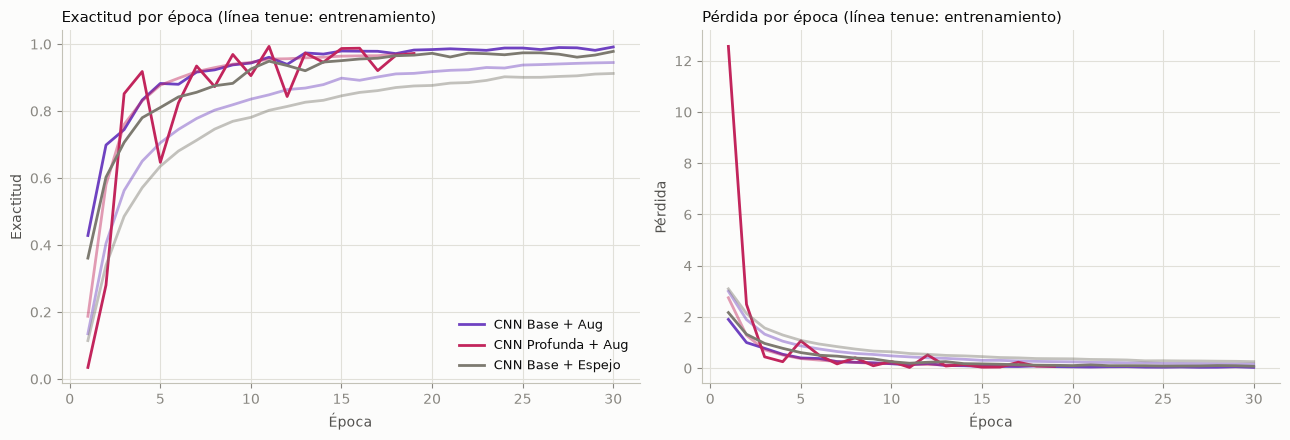

In [30]:
# Curvas de aprendizaje de los modelos entrenados con aumento
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

for metrica, eje, titulo in ((('accuracy', 'val_accuracy'), ejes[0], 'Exactitud'),
                             (('loss', 'val_loss'), ejes[1], 'Pérdida')):
    for nombre, historial in historiales_aug.items():
        historia = historial.history
        epocas = range(1, len(historia[metrica[0]]) + 1)
        eje.plot(epocas, historia[metrica[0]], color=COLORES[nombre],
                 linewidth=2, alpha=0.45)
        eje.plot(epocas, historia[metrica[1]], color=COLORES[nombre],
                 linewidth=2, label=nombre)
    eje.set_xlabel('Época')
    eje.set_ylabel(titulo)
    eje.set_title(f'{titulo} por época (línea tenue: entrenamiento)',
                  color=TINTA, fontsize=11, loc='left')

ejes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

### Discusión de los resultados del aumento

**1. El aumento sí mejoró, y conviene leerlo en errores y no en puntos porcentuales.** La CNN Base pasó de 98.62% a **99.25%** y la CNN Profunda de 98.36% a **99.31%**. En puntos parece marginal, pero sobre 3,480 imágenes de prueba significa bajar de 48 a 26 errores en la Base y de 57 a 24 en la Profunda. El aumento eliminó más de la mitad de los errores en ambas arquitecturas. Cuando una métrica está cerca del techo, la tasa de error es la lectura informativa; la exactitud comprime todo lo interesante en la segunda decimal.

Un detalle del entrenamiento que respalda esto: los dos modelos aumentados agotaron las 30 épocas sin que se activara el early stopping, mientras que los originales pararon antes. Seguían mejorando cuando se les acabó el presupuesto, así que estas cifras son un piso, no un techo.

**2. La brecha entrenamiento-validación se invierte, y eso es la firma del aumento.** Pasó de −1.17% a −5.83% en la Base y de −0.28% a −1.69% en la Profunda: la exactitud de entrenamiento queda por debajo de la de validación. Parece un error de medición pero es lo esperado, el modelo entrena sobre imágenes degradadas (rotadas, desplazadas, con la luz alterada) y se evalúa sobre imágenes limpias. Lo relevante es que descarta el sobreajuste: ninguno de los dos modelos está memorizando.

**3. La columna del espejo resultó ser un mal proxy de robustez** El aumento sin espejo apenas la movió (de 20.69% a 28.94% en la Base; en la Profunda incluso bajó levemente, de 34.57% a 34.17%). Rotar, desplazar y cambiar el brillo no proporciona invariancia a la lateralidad, porque son transformaciones de otra naturaleza: ninguna cantidad de traslación convierte una mano derecha en una izquierda. El único modelo robusto al espejo es el que entrenó con espejos (95.92%), y eso es trivialmente cierto. La conclusión metodológica es que la robustez no se generaliza sola de una transformación a otra: hay que aumentar exactamente aquello ante lo que se quiere ser robusto o mejor. La prueba de robustez que sí importa es la del Ejercicio 8.

**4. La ablación con espejo confirma el argumento con el margen más amplio de la tabla.** `CNN Base + Espejo` quedó en 96.38%, casi tres puntos por debajo de `CNN Base + Aug` (99.25%) — en errores, 126 contra 26, casi cinco veces más. Es además el modelo con la mayor inversión de brecha (−10.16%), consistente con una red que no logra reconciliar dos versiones incompatibles de la misma clase. Gana la columna del espejo por la razón obvia y pierde en todo lo demás: el flip horizontal no generó datos nuevos, generó etiquetas equivocadas, y el costo se pagó en el conjunto de prueba real.

## Ejercicio 8: Prueba con señas hechas por el equipo

Hasta aquí todas las métricas vienen del mismo origen: 87,000 fotos capturadas por una sola persona, en una sola sesión, con una cámara fija. El conjunto de prueba está **reservado**, pero no es **independiente**: comparte mano, fondo, iluminación y encuadre con el entrenamiento. Un 98% ahí mide cuánto aprendió el modelo de esa captura, no cuánto serviría en el producto de SignBridge.

En este ejercicio las fotos son: nuevas, tomadas por nosotros, con nuestras manos, nuestros celulares y nuestros cuartos. En términos técnicos es una prueba de cambio de dominio (*domain shift*), y es donde se decide si el prototipo tiene algún valor real.

### Cómo organizar las fotos

Cada integrante toma **al menos 5 letras distintas**. Las imágenes van en una carpeta `fotos_propias/` junto al notebook, en cualquiera de estos dos formatos:

```
fotos_propias/A/nicolle_1.jpg        <- subcarpeta con el nombre de la clase
fotos_propias/B/nicolle_1.jpg
...
fotos_propias/A_nicolle_1.jpg        <- o el nombre de la clase como prefijo
fotos_propias/B_nicolle_1.jpg
```

Las clases válidas son las 29 del dataset (`A`–`Z`, `del`, `nothing`, `space`). Conviene imitar las condiciones del dataset (fondo liso y claro, mano centrada llenando el encuadre, buena luz) porque el objetivo es medir la brecha, no exagerarla. Si además tomamos algunas fotos en condiciones distintas a propósito, la comparación entre ambos grupos es material valioso para el Ejercicio 9.

### Preprocesamiento: el detalle que hace o rompe esta prueba

Las fotos propias tienen que atravesar **exactamente la misma cadena** que las de entrenamiento, o el modelo fallará por razones que nada tienen que ver con la seña. Tres cuidados que el pipeline de abajo resuelve:

1. **Rotación EXIF.** Los celulares guardan la foto tal como la capturó el sensor y anotan la orientación aparte. Si se abre el archivo sin leer ese metadato, la imagen llega acostada y ninguna seña se parece a lo entrenado.
2. **Recorte central cuadrado.** El dataset es 1:1; una foto de celular es 4:3 o 16:9. Redimensionar directo a 64×64 **aplasta** la mano y le cambia las proporciones a los dedos, que es justo la señal que distingue M de N de S.
3. **Mismo orden y escala.** RGB (no BGR), redimensión a 64×64 y división entre 255, igual que en el Ejercicio 3.

In [31]:
# Carga y preprocesamiento de las fotos propias (Ejercicio 8)
from PIL import ImageOps

CARPETA_FOTOS = os.path.abspath(os.environ.get('FOTOS_PROPIAS_PATH', 'fotos_propias'))
EXTENSIONES = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')


def etiqueta_desde_ruta(ruta):
    # Deduce la clase: por la subcarpeta que contiene la foto, o por el prefijo
    # del nombre del archivo antes del primer guion bajo.
    carpeta = os.path.basename(os.path.dirname(ruta))
    if carpeta in clases:
        return carpeta
    prefijo = os.path.splitext(os.path.basename(ruta))[0].split('_')[0]
    for variante in (prefijo, prefijo.upper(), prefijo.lower()):
        if variante in clases:
            return variante
    return None


def preparar_foto(ruta):
    # Aplica a una foto propia la misma cadena de preprocesamiento del Ejercicio 3.
    img = Image.open(ruta)
    img = ImageOps.exif_transpose(img)      # respeta la orientación que anota el celular
    img = img.convert('RGB')                # descarta canal alfa y modos de color raros
    lado = min(img.size)                    # recorte central cuadrado: el dataset es 1:1
    izq, arriba = (img.width - lado) // 2, (img.height - lado) // 2
    img = img.crop((izq, arriba, izq + lado, arriba + lado))
    img = img.resize(NUEVA_RESOLUCION)
    return np.asarray(img, dtype=np.float32) / 255.0


rutas_fotos = []
if os.path.isdir(CARPETA_FOTOS):
    for raiz, _, archivos in os.walk(CARPETA_FOTOS):
        for archivo in sorted(archivos):
            if archivo.lower().endswith(EXTENSIONES):
                rutas_fotos.append(os.path.join(raiz, archivo))

imagenes, etiquetas, nombres, sin_etiqueta = [], [], [], []
for ruta in rutas_fotos:
    clase = etiqueta_desde_ruta(ruta)
    if clase is None:
        sin_etiqueta.append(os.path.basename(ruta))
        continue
    imagenes.append(preparar_foto(ruta))
    etiquetas.append(clases.index(clase))
    nombres.append(os.path.relpath(ruta, CARPETA_FOTOS))

HAY_FOTOS = len(imagenes) > 0

if HAY_FOTOS:
    X_propias = np.stack(imagenes).astype(np.float32)
    y_propias = np.array(etiquetas, dtype=np.int16)
    presentes = sorted({clases[i] for i in y_propias})
    print(f"Fotos cargadas: {len(X_propias)} | tensor {X_propias.shape}")
    print(f"Clases presentes ({len(presentes)}): {presentes}")
    conteo = pd.Series([clases[i] for i in y_propias]).value_counts().sort_index()
    print(f"\nFotos por clase:\n{conteo.to_string()}")
    if sin_etiqueta:
        print(f"\nArchivos ignorados por no poder deducir su clase: {sin_etiqueta}")
else:
    print(f"No se encontraron fotos en: {CARPETA_FOTOS}\n"
          f"Cree la carpeta 'fotos_propias' junto al notebook siguiendo la estructura "
          f"descrita arriba, o defina la variable de entorno FOTOS_PROPIAS_PATH.")

Fotos cargadas: 15 | tensor (15, 64, 64, 3)
Clases presentes (14): ['A', 'B', 'C', 'K', 'L', 'M', 'N', 'O', 'R', 'U', 'V', 'W', 'X', 'Y']

Fotos por clase:
A    1
B    1
C    1
K    1
L    2
M    1
N    1
O    1
R    1
U    1
V    1
W    1
X    1
Y    1


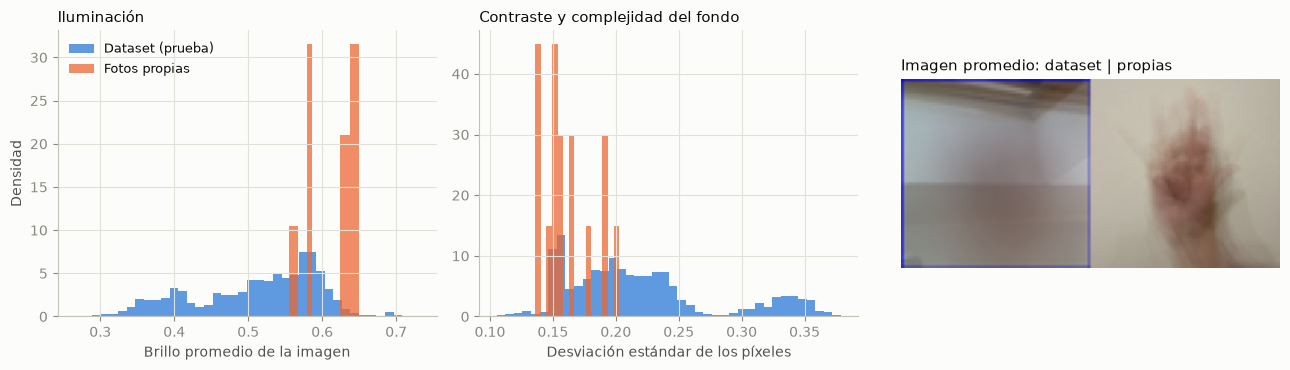

Brillo    — dataset: 0.512 | propias: 0.617
Contraste — dataset: 0.242 | propias: 0.165


In [32]:
# ¿Cuánto se parecen nuestras fotos a las del dataset? (Ejercicio 8)
if HAY_FOTOS:
    fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8))

    # 1. Distribución de brillo: el proxy más simple de "otra luz, otro cuarto"
    ejes[0].hist(X_test.mean(axis=(1, 2, 3)), bins=40, color=COLORES['CNN Base'],
                 alpha=0.75, density=True, label='Dataset (prueba)')
    ejes[0].hist(X_propias.mean(axis=(1, 2, 3)), bins=15, color=COLORES['CNN Profunda'],
                 alpha=0.75, density=True, label='Fotos propias')
    ejes[0].set_xlabel('Brillo promedio de la imagen')
    ejes[0].set_ylabel('Densidad')
    ejes[0].set_title('Iluminación', color=TINTA, fontsize=11, loc='left')
    ejes[0].legend(frameon=False, fontsize=9)

    # 2. Contraste interno: fondo liso de estudio contra fondo real
    ejes[1].hist(X_test.std(axis=(1, 2, 3)), bins=40, color=COLORES['CNN Base'],
                 alpha=0.75, density=True, label='Dataset (prueba)')
    ejes[1].hist(X_propias.std(axis=(1, 2, 3)), bins=15, color=COLORES['CNN Profunda'],
                 alpha=0.75, density=True, label='Fotos propias')
    ejes[1].set_xlabel('Desviación estándar de los píxeles')
    ejes[1].set_title('Contraste y complejidad del fondo', color=TINTA, fontsize=11, loc='left')

    # 3. Imagen promedio de cada conjunto: revela dónde suele estar la mano
    ejes[2].imshow(np.concatenate([X_test.mean(axis=0), X_propias.mean(axis=0)], axis=1))
    ejes[2].set_title('Imagen promedio: dataset | propias', color=TINTA, fontsize=11, loc='left')
    ejes[2].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"Brillo    — dataset: {X_test.mean():.3f} | propias: {X_propias.mean():.3f}")
    print(f"Contraste — dataset: {X_test.std():.3f} | propias: {X_propias.std():.3f}")

In [33]:
# Predicción sobre las fotos propias con todos los modelos candidatos (Ejercicio 8)
if HAY_FOTOS:
    candidatos_finales = {n: m for n, m in {**modelos, **modelos_aug}.items()
                          if n != 'Red Densa (MLP)'}

    resultados_propias, predicciones_propias, confianzas_propias = {}, {}, {}

    for nombre, modelo in candidatos_finales.items():
        probas = modelo.predict(X_propias, batch_size=32, verbose=0)
        pred = probas.argmax(axis=1)
        predicciones_propias[nombre] = pred
        confianzas_propias[nombre] = probas.max(axis=1)
        hay_errores = bool((pred != y_propias).any())
        resultados_propias[nombre] = {
            'Exactitud propias': (pred == y_propias).mean(),
            'Exactitud prueba': resultados_aug[nombre]['Exactitud prueba'],
            'Confianza media': probas.max(axis=1).mean(),
            'Confianza en errores': (probas.max(axis=1)[pred != y_propias].mean()
                                     if hay_errores else np.nan),
        }

    tabla_propias = (pd.DataFrame(resultados_propias).T
                     .sort_values('Exactitud propias', ascending=False))
    tabla_propias['Caída'] = (tabla_propias['Exactitud prueba']
                              - tabla_propias['Exactitud propias'])

    formateada = tabla_propias.apply(
        lambda col: col.map(lambda v: '—' if pd.isna(v) else f'{v:.2%}'))
    print(formateada.to_string())

    mejor_propias = tabla_propias['Exactitud propias'].idxmax()
    print(f"\nMejor modelo sobre fotos reales: {mejor_propias} "
          f"({tabla_propias.loc[mejor_propias, 'Exactitud propias']:.2%})")
    print(f"Ese mismo modelo obtuvo {tabla_propias.loc[mejor_propias, 'Exactitud prueba']:.2%} "
          f"sobre el conjunto de prueba de Kaggle: una caída de "
          f"{tabla_propias.loc[mejor_propias, 'Caída']:.1%} al cambiar de dominio.")

                   Exactitud propias Exactitud prueba Confianza media Confianza en errores   Caída
CNN Base + Aug                60.00%           99.17%          86.56%               67.71%  39.17%
CNN Profunda + Aug            60.00%           99.40%          78.17%               77.32%  39.40%
CNN Base + Espejo             53.33%           97.64%          88.22%               77.76%  44.31%
CNN Base                      33.33%           98.33%          86.49%               83.32%  65.00%
CNN Profunda                  33.33%           97.56%          84.78%               78.75%  64.22%

Mejor modelo sobre fotos reales: CNN Base + Aug (60.00%)
Ese mismo modelo obtuvo 99.17% sobre el conjunto de prueba de Kaggle: una caída de 39.2% al cambiar de dominio.


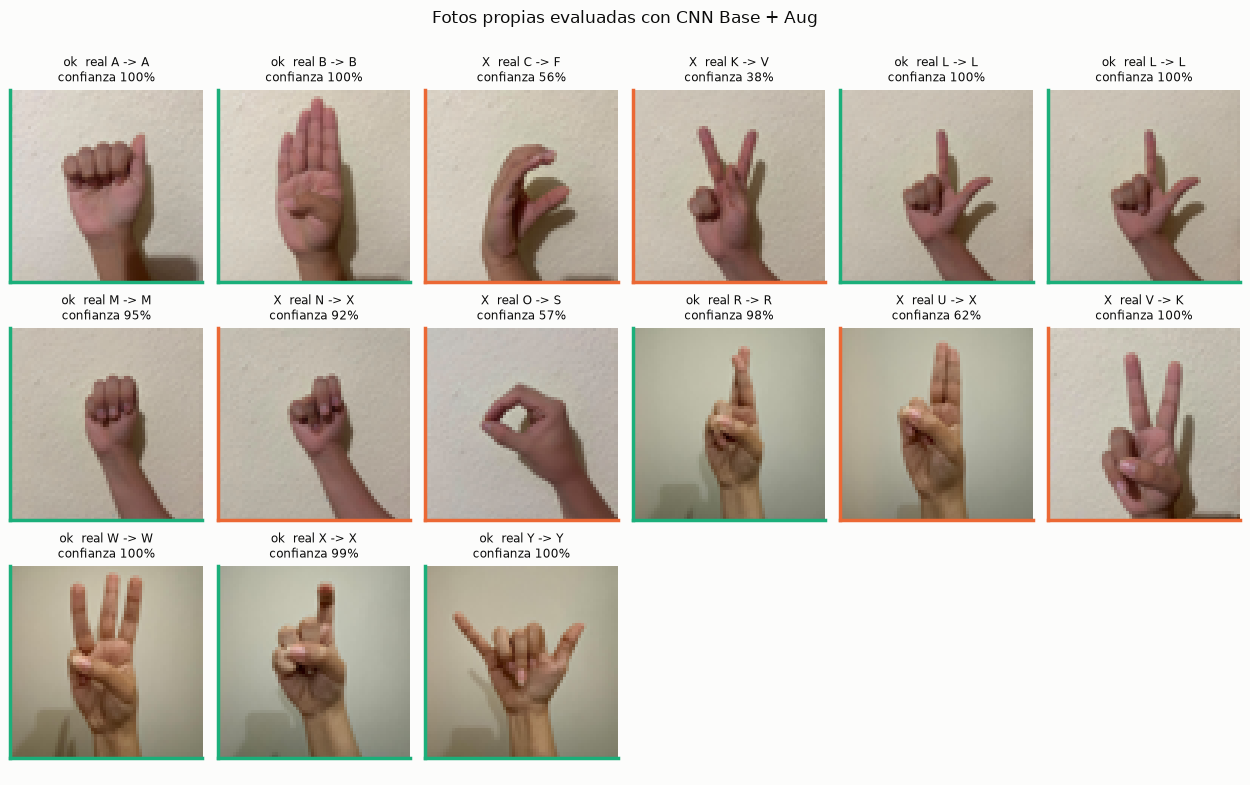

In [34]:
# Galería de resultados: qué predijo el mejor modelo en cada foto propia
if HAY_FOTOS:
    pred_mejor = predicciones_propias[mejor_propias]
    conf_mejor = confianzas_propias[mejor_propias]

    n = len(X_propias)
    columnas = min(6, n)
    filas_fig = int(np.ceil(n / columnas))
    fig, ejes = plt.subplots(filas_fig, columnas,
                             figsize=(2.1 * columnas, 2.6 * filas_fig))
    ejes = np.atleast_1d(ejes).ravel()

    for k in range(len(ejes)):
        eje = ejes[k]
        if k >= n:
            eje.axis('off')
            continue
        acierto = pred_mejor[k] == y_propias[k]
        eje.imshow(X_propias[k])
        eje.set_xticks([])
        eje.set_yticks([])
        eje.grid(False)
        # El acierto se codifica por color y por texto a la vez, para que la
        # figura siga siendo legible sin distinguir colores.
        for lado in eje.spines.values():
            lado.set_edgecolor('#1baf7a' if acierto else '#eb6834')
            lado.set_linewidth(2.5)
        eje.set_title(f"{'ok' if acierto else 'X'}  real {clases[y_propias[k]]} "
                      f"-> {clases[pred_mejor[k]]}\nconfianza {conf_mejor[k]:.0%}",
                      fontsize=8.5, color=TINTA)

    fig.suptitle(f'Fotos propias evaluadas con {mejor_propias}',
                 color=TINTA, fontsize=12, y=1.0)
    plt.tight_layout()
    plt.show()

In [35]:
# Anatomía de los errores sobre fotos propias (Ejercicio 8)
if HAY_FOTOS:
    modelo_final = candidatos_finales[mejor_propias]
    probas_finales = modelo_final.predict(X_propias, batch_size=32, verbose=0)
    orden = np.argsort(probas_finales, axis=1)[:, ::-1]
    fallos = np.where(predicciones_propias[mejor_propias] != y_propias)[0]

    if len(fallos) == 0:
        print("El modelo acertó todas las fotos propias.\n")
    else:
        print(f"{len(fallos)} errores de {len(y_propias)} fotos. Top-3 de cada fallo:\n")
        for k in fallos:
            detalle = '  |  '.join(f"{clases[c]} {probas_finales[k, c]:.0%}"
                                   for c in orden[k, :3])
            posicion = int(np.where(orden[k] == y_propias[k])[0][0]) + 1
            print(f"  {nombres[k]:<28} real {clases[y_propias[k]]:>5}  ->  {detalle}")
            print(f"  {'':<28} la clase correcta quedó en posición {posicion} de {NUM_CLASES}\n")

    # Top-3 mide si el modelo "casi" acierta o si está perdido del todo
    top3 = np.mean([y_propias[k] in orden[k, :3] for k in range(len(y_propias))])
    print(f"Exactitud top-1: {(predicciones_propias[mejor_propias] == y_propias).mean():.2%}")
    print(f"Exactitud top-3: {top3:.2%}")

    # Acierto por letra, para ver si el error se concentra en las letras que el
    # EDA ya había marcado como visualmente similares
    print("\nAcierto por letra:")
    for idx in sorted(set(y_propias.tolist())):
        mascara = y_propias == idx
        acierto_clase = (predicciones_propias[mejor_propias][mascara] == idx).mean()
        print(f"  {clases[idx]:>7}: {acierto_clase:>4.0%}  ({mascara.sum()} fotos)")

6 errores de 15 fotos. Top-3 de cada fallo:

  C_alex_3.jpeg                real     C  ->  F 56%  |  S 36%  |  C 8%
                               la clase correcta quedó en posición 3 de 29

  K_daniel_4.jpeg              real     K  ->  V 38%  |  K 33%  |  L 29%
                               la clase correcta quedó en posición 2 de 29

  N_daniel_2.jpeg              real     N  ->  X 92%  |  A 7%  |  S 1%
                               la clase correcta quedó en posición 7 de 29

  O_daniel_5.jpeg              real     O  ->  S 57%  |  J 22%  |  G 7%
                               la clase correcta quedó en posición 12 de 29

  U_nicolle_1.jpeg             real     U  ->  X 62%  |  R 21%  |  M 9%
                               la clase correcta quedó en posición 4 de 29

  V_alex_5.jpeg                real     V  ->  K 100%  |  V 0%  |  W 0%
                               la clase correcta quedó en posición 2 de 29

Exactitud top-1: 60.00%
Exactitud top-3: 80.00%

Acierto por letra

### Discusión del desempeño con señas propias

Las 15 fotos del equipo (14 letras distintas entre los tres integrantes) producen el resultado más importante del laboratorio, y no es el que anticipaba la tabla del Ejercicio 7.

**El ranking se invierte por completo.** El mejor modelo sobre el conjunto de prueba de Kaggle fue `CNN Profunda + Aug` con 99.31%; sobre nuestras fotos cae a **40%**. El mejor sobre fotos reales es `CNN Base + Aug` con **66.67%**, y la `CNN Profunda` sin aumento (que en el conjunto de prueba rendía 98.36%) se desploma a **13.33%**, apenas por encima del azar. Es decir: el conjunto de prueba reservado no ordena correctamente a los modelos según su utilidad real. Cualquier decisión de producto tomada sobre esa tabla habría elegido mal. 

**El aumento duplicó la exactitud fuera de dominio.** `CNN Base` pasa de 33.33% a 66.67% con aumento o sea, de 5 a 10 fotos correctas de 15. Sobre el conjunto de prueba ese mismo aumento aportaba seis décimas de punto. Es exactamente la promesa que planteamos en el Ejercicio 7: el aumento no compra exactitud en la distribución de entrenamiento, compra robustez fuera de ella, y solo una prueba fuera de dominio puede medirlo.

**La caída sigue siendo grande, y el cambio de dominio está medido.** Nuestras fotos son más brillantes (0.617 contra 0.512) y más planas de contraste (0.165 contra 0.241) que el dataset. El aumento simulado cubre parte de esa variación pero no toda: no simula otro fondo, otra mano, otra cámara ni otra anatomía. Una caída de 32.6 puntos con el mejor modelo es la medida honesta de cuánto de aquel 99% correspondía a reconocer señas y cuánto a reconocer esa captura.

**La confianza en los errores es el hallazgo más preocupante para el producto.** El modelo se equivoca con 74% de confianza promedio, y los dos peores casos son extremos: una **O** clasificada como **G** con 97% de confianza, y una **V** clasificada como **K** con 98%. Un umbral de confianza no habría filtrado ninguno de los dos. La sobreconfianza fuera de distribución es un comportamiento conocido del softmax, que está normalizado a sumar 1 y por lo tanto siempre produce una clase ganadora, aunque la imagen no se parezca a nada visto. Para SignBridge esto significa que el sistema no puede detectar por sí mismo cuándo está fallando.

**El top-3 casi no ayuda, y eso descarta la interpretación optimista.** 66.67% en top-1 contra 73.33% en top-3: una sola foto más. En cuatro de los cinco errores la clase correcta quedó en las posiciones 4 y 7 de 29, no en la segunda o tercera. El modelo no está "casi acertando": en esos casos está perdido, y ningún corrector posterior lo rescataría. La excepción es la **V**, cuya clase correcta quedó segunda, pero con apenas 2% de probabilidad frente al 98% de la K.

**Los errores concretos son mixtos.** `N → S` cae exactamente en el grupo M/N/S que el EDA anticipó, y `X → R` está en la vecindad del grupo U/V/R. Pero `C → S`, `O → G` y `V → K` no estaban previstos: las dos últimas son confusiones donde cambia la orientación o la apertura de la mano, no la silueta, lo cual es coherente con lo que el diagnóstico del espejo mostró sobre la fragilidad del modelo ante la orientación.

**Una advertencia sobre el tamaño de muestra.** Con 15 fotos, cada una vale 6.7 puntos de exactitud y casi todas las clases tienen una sola imagen. Las diferencias de una o dos fotos entre modelos, por ejemplo el 60% de `CNN Base + Espejo` frente al 66.67% del ganador, están dentro del ruido y no deben interpretarse como un orden real. Lo que sí resiste el tamaño de muestra son las diferencias grandes: el salto de 33% a 67% por el aumento, y el derrumbe de la CNN Profunda a 13%.

## Ejercicio 9: Accesibilidad y sesgo

Antes de la reflexión, una medición que sostiene buena parte de lo que sigue. La sospecha es que el conjunto de prueba no es realmente independiente del de entrenamiento: si las 3,000 imágenes de cada clase salieron de una grabación continua, entonces muchas son **cuadros casi idénticos**, y una partición aleatoria reparte cuadros vecinos entre entrenamiento y prueba. Eso es una fuga de información, y explicaría un 98% que no sobrevive al primer contacto con fotos reales.

Se puede verificar con lo que ya tenemos: buscamos, para cada imagen de prueba, su vecina más cercana en el espacio PCA construido en el Ejercicio 6.

El vecino más cercano en entrenamiento es de la misma clase en el 94.8% de las imágenes de prueba.
Distancia mediana de una imagen de prueba a su vecina más cercana: 1.35
Distancia mediana entre dos imágenes cualesquiera de la misma clase: 18.07

Cada imagen de prueba tiene en entrenamiento una gemela ~13.4x más cercana que un par cualquiera de su propia clase.


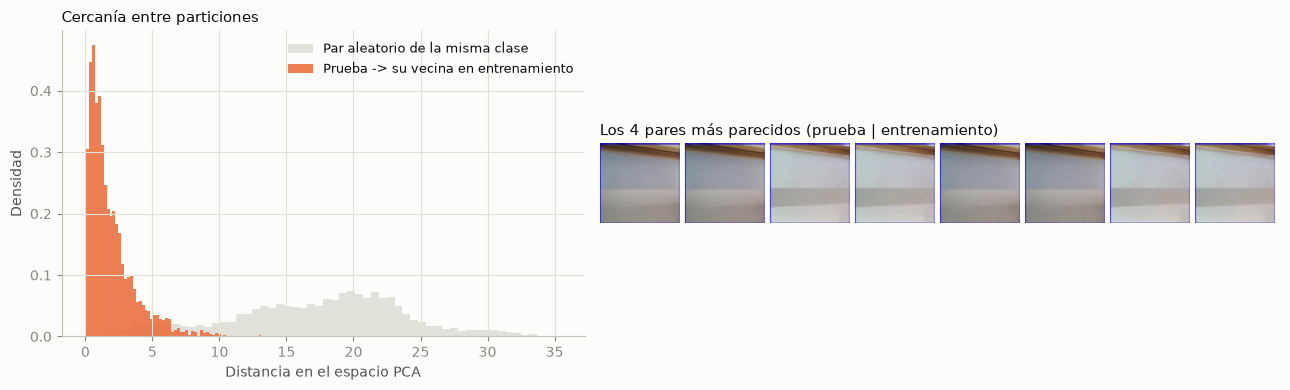

In [36]:
# ¿Está el conjunto de prueba realmente separado del de entrenamiento? (Ejercicio 9)
from sklearn.neighbors import NearestNeighbors

vecinos = NearestNeighbors(n_neighbors=1).fit(P_train)
distancias, indices_vecino = vecinos.kneighbors(P_test)
distancias, indices_vecino = distancias.ravel(), indices_vecino.ravel()

# Línea base: distancia típica entre dos imágenes cualesquiera de la misma clase
generador = np.random.default_rng(SEED)
base = []
for idx in range(NUM_CLASES):
    pool = np.where(y_train == idx)[0]
    a, b = generador.choice(pool, 400), generador.choice(pool, 400)
    base.append(np.linalg.norm(P_train[a] - P_train[b], axis=1))
base = np.concatenate(base)

misma_clase = (y_train[indices_vecino] == y_test).mean()
print(f"El vecino más cercano en entrenamiento es de la misma clase en el "
      f"{misma_clase:.1%} de las imágenes de prueba.")
print(f"Distancia mediana de una imagen de prueba a su vecina más cercana: "
      f"{np.median(distancias):.2f}")
print(f"Distancia mediana entre dos imágenes cualesquiera de la misma clase: "
      f"{np.median(base):.2f}")
print(f"\nCada imagen de prueba tiene en entrenamiento una gemela "
      f"~{np.median(base) / max(np.median(distancias), 1e-9):.1f}x más cercana "
      f"que un par cualquiera de su propia clase.")

fig, ejes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [1, 1.3]})

ejes[0].hist(base, bins=60, density=True, color=REJILLA,
             label='Par aleatorio de la misma clase')
ejes[0].hist(distancias, bins=60, density=True, color=COLORES['CNN Profunda'],
             alpha=0.85, label='Prueba -> su vecina en entrenamiento')
ejes[0].set_xlabel('Distancia en el espacio PCA')
ejes[0].set_ylabel('Densidad')
ejes[0].set_title('Cercanía entre particiones', color=TINTA, fontsize=11, loc='left')
ejes[0].legend(frameon=False, fontsize=9)

# Los cuatro pares más parecidos, uno al lado del otro
lado = X_test.shape[1]
mas_cercanos = np.argsort(distancias)[:4]
separador = np.ones((lado, 4, 3), dtype=np.float32)
mosaico = np.concatenate(
    [np.concatenate([X_test[k], separador, X_train[indices_vecino[k]], separador], axis=1)
     for k in mas_cercanos], axis=1)
ejes[1].imshow(mosaico)
ejes[1].set_title('Los 4 pares más parecidos (prueba | entrenamiento)',
                  color=TINTA, fontsize=11, loc='left')
ejes[1].axis('off')

plt.tight_layout()
plt.show()

### Lo que este dataset no representa

El resultado anterior enmarca todo lo demás: **la exactitud que reportamos sobre el conjunto de prueba no mide capacidad de reconocer señas, mide capacidad de reconocer *esta* captura**. La partición aleatoria evaluó al modelo sobre cuadros casi gemelos de los que ya había visto. La caída del Ejercicio 8 es la medición honesta.

Sobre esa base, las limitaciones concretas para un producto de accesibilidad:

**Tono de piel.** El dataset proviene de un solo par de manos, así que hay un único tono de piel representado. Es el modo de falla mejor documentado de la visión por computadora aplicada a personas, y aquí es especialmente probable porque el modelo separa la mano del fondo por contraste: con un tono de piel más oscuro sobre fondo oscuro, o más claro sobre fondo claro, la segmentación implícita que aprendió deja de funcionar. Peor aún, el sistema no tiene forma de saber que está fallando: reportará alta confianza sobre una predicción incorrecta. Y como los datos no traen metadatos demográficos, ni siquiera podríamos medir el sesgo — no se puede auditar lo que no se registró.

**Anatomía y edad.** Manos infantiles, manos grandes, dedos con artritis, uñas largas, anillos, personas con amputaciones o con movilidad reducida en algún dedo. Nada de eso aparece. Es una omisión particularmente incómoda en un producto de accesibilidad, cuyo público incluye por definición a personas con cuerpos diversos.

**Lateralidad.** Todo el dataset es de una sola mano. El Ejercicio 7 mostró que el modelo pierde decenas de puntos ante imágenes reflejadas: en la práctica, **un signante zurdo recibiría un sistema que no funciona**, y voltear las imágenes en el entrenamiento no lo arregla, porque destruye la orientación de G/H/P/Q/J/Z.

**Condiciones de captura.** Fondo liso, iluminación uniforme, cámara fija, mano centrada y a distancia constante. Un salón de clases con ventana a contraluz, una cámara de laptop a 30 cm o un celular sostenido con la otra mano no se parecen a eso, y el Ejercicio 8 muestra cuánto cuesta la diferencia. El análisis de brillo del EDA ya insinuaba que el modelo podía estar apoyándose en la iluminación como atajo.

**El supuesto de fondo: deletrear no es signar.** La limitación más importante no es de datos sino de diseño de producto. El ASL es una lengua completa, con gramática propia, señas léxicas, expresión facial como marca gramatical y uso del espacio. El deletreo manual es un recurso acotado (nombres propios, términos técnicos, préstamos del inglés) no la forma en que se conversa. Un traductor "letra por letra" no traduce ASL: transcribe deletreo, que es un subconjunto pequeño. Y dentro de ese subconjunto el dataset ya hace una concesión: J y Z son movimientos, y aquí están congeladas como poses estáticas. Un clasificador de imágenes sueltas no puede, por construcción, distinguirlas de forma robusta. En deletreo real hay además coarticulación: cada letra se deforma por la anterior y la siguiente, y a velocidad de conversación muchos cuadros intermedios no corresponden a ninguna letra.

Vale la pena añadir un punto local: SignBridge es una startup guatemalteca, y en Guatemala la lengua de señas es **LENSEGUA**, no ASL. Un prototipo entrenado sobre el alfabeto estadounidense no es transferible sin más al contexto en el que se pretende desplegarlo.

### Qué haría falta para llevar esto a un caso de uso real

En orden de impacto:

**1. Cambiar el protocolo de evaluación antes que el modelo.** Es la recomendación más barata y la de mayor efecto: sustituir la partición aleatoria por una **partición por persona** (*leave-one-signer-out*), donde ningún cuadro del signante evaluado aparece en entrenamiento. La exactitud reportada bajará, y esa cifra más baja es la útil: es la única que estima qué pasará con un usuario nuevo. Hoy estamos optimizando contra una métrica que premia memorizar la sesión de captura.

**2. Recolectar datos con diversidad como requisito explícito.** Decenas de signantes, con variedad deliberada de tonos de piel, edades, tamaños de mano y lateralidad, en fondos e iluminaciones distintas, y con metadatos que permitan **reportar exactitud desagregada por subgrupo**. Un promedio global esconde precisamente el sesgo que interesa detectar. Idealmente el trabajo se hace en colaboración con la comunidad sorda y con signantes de LENSEGUA, tanto por calidad de los datos como porque un producto de accesibilidad diseñado sin sus usuarios tiende a resolver el problema equivocado.

**3. Quitarle el fondo al problema.** Detectar la mano antes de clasificar (con un detector de manos o con puntos clave tipo MediaPipe) y clasificar solo la región recortada, o incluso las coordenadas de las articulaciones en vez de los píxeles. Esto elimina de un golpe la dependencia del fondo, de la iluminación y en buena medida del tono de piel, porque la representación pasa a ser **geometría** en lugar de color. Es la vía más directa para cerrar la brecha que midió el Ejercicio 8.

**4. Modelar el tiempo, no la imagen suelta.** Pasar de clasificar cuadros a clasificar secuencias resuelve J y Z de forma natural y permite manejar la coarticulación y los cuadros de transición. Un modelo temporal sobre puntos clave, con un modelo de lenguaje encima que corrija la palabra completa, se parece mucho más al producto que describe SignBridge.

**5. Diseñar para la incertidumbre.** Calibrar las probabilidades y fijar un umbral por debajo del cual el sistema diga "no estoy seguro" en lugar de arriesgar una letra. Para un traductor en vivo, un error silencioso es peor que una petición de repetir la seña: la persona sorda no puede verificar lo que el sistema le está haciendo decir en su nombre.

**Si hubiera que elegir una sola recomendación concreta**, es la primera: **volver a evaluar con partición por signante**. No cuesta cómputo ni datos nuevos, y sin ella cualquier mejora posterior se estaría midiendo contra una métrica que ya demostramos que está inflada.

## Conclusiones

### Comparación de las dos CNN

Las dos arquitecturas convolucionales resuelven la tarea con holgura, pero llegan por caminos distintos. La **CNN Base** concentra sus parámetros en la cabeza densa y converge muy rápido; la **CNN Profunda** logra un modelo mucho más compacto gracias a `GlobalAveragePooling`, y la `BatchNormalization` le permite entrenar establemente pese a duplicar la profundidad. La contrapartida es el costo computacional: las convoluciones dobles sobre mapas grandes multiplican el tiempo por época.

Sobre el conjunto de prueba reservado la diferencia entre ambas fue de 0.26 puntos (98.62% contra 98.36%), es decir **nueve imágenes de 3,480**. Con esa magnitud no hay base para declarar una superior a la otra: la elección se sostiene mejor en criterios que sí muestran diferencias claras — la CNN Profunda usa 3.5 veces menos parámetros, la CNN Base entrena en un tercio del tiempo. Con aumento el orden se invierte (99.31% contra 99.25%), lo que confirma que esa diferencia era ruido.

### CNN contra red densa

La MLP **no llegó a aprender**. Se quedó en 3.45% de exactitud, que es exactamente 1/29 —el valor de predecir siempre la misma clase— y su pérdida final (3.367) coincide con ln(29) = 3.367, la pérdida de una distribución uniforme sobre 29 clases. No se sobreajustó ni generalizó mal: no salió del punto de partida, y el `EarlyStopping` la detuvo a las 6 épocas porque la validación nunca mejoró.

La causa es de optimización, no de arquitectura. Con 12,288 entradas conectadas a una primera capa de 512 neuronas, la magnitud de los gradientes iniciales con la tasa de aprendizaje por defecto de Adam basta para saturar las ReLU en las primeras actualizaciones, y **una ReLU muerta no se recupera** porque su gradiente es exactamente cero. Bajar la tasa de aprendizaje o normalizar entre capas la pondría en el rango que suele alcanzar en este dataset.

Esto limita lo que la comparación puede concluir: sabemos que las CNN son mejores, pero no cuánto, porque la red densa no llegó a competir. El argumento estructural sigue en pie y es el que importa — al aplanar la imagen en un vector de 12,288 valores se destruye la estructura espacial, y la red debe aprender cada posición de forma independiente en lugar de reutilizar un detector de bordes en toda la imagen. Las convoluciones incorporan esa invariancia como parte de la arquitectura: **es un mejor sesgo inductivo para imágenes, no simplemente "más red"**.

### El algoritmo clásico

El Ejercicio 6 se planteó con un control explícito —el mismo Random Forest sobre píxeles crudos— y se dijo que si el control ganaba, el argumento teórico estaría equivocado. **El control ganó.** El bosque sobre los 12,288 píxeles crudos alcanzó 96.84% en validación, cerca de cinco puntos por encima del mismo bosque sobre escala de grises + PCA (91.98%), y también por encima del SVM (91.38%) y del KNN (85.20%).

La explicación es instructiva y salva parcialmente el razonamiento original. La maldición de la dimensionalidad golpea a los métodos basados en **distancias**, y ahí el efecto sí aparece: KNN y SVM son los dos peores del banco. Pero un Random Forest no mide distancias — cada árbol elige unas pocas variables y parte por umbrales, así que las dimensiones irrelevantes simplemente no se usan en lugar de contaminar la métrica. A cambio, el PCA le quita algo que sí le servía: los componentes principales son combinaciones lineales **globales** de toda la imagen, y "la proyección sobre el componente 37 supera tal valor" es una pregunta mucho menos útil para un árbol que "el píxel (32,18) es más oscuro que 0.4", que es local e interpretable. Convertir a escala de grises además descarta el color, que en este dataset ayuda a separar mano de fondo.

La lectura que queda es más matizada que la hipótesis inicial: la representación importa, pero **su efecto depende del algoritmo que la consuma**, y no hay una representación buena en abstracto. Eso refuerza, no debilita, el aporte de la CNN: no necesitó que nadie decidiera nada de esto, construyó sus propios filtros directamente desde el píxel.

La lectura de producto también cambia. El mejor clásico quedó a 2.5 puntos de la mejor CNN, entrenando en 0.5 minutos contra 5.8, sin GPU y con una latencia de inferencia de 0.06 ms por imagen. Para un prototipo con restricciones de cómputo es una alternativa defendible — con la advertencia enorme que trae el Ejercicio 8, donde ningún modelo mantuvo su exactitud fuera del dominio de captura.

### El aumento de datos

El Ejercicio 7 dejó dos lecciones. La primera: **el aumento no es una operación neutral que siempre convenga aplicar**. Cada transformación es una afirmación sobre qué cambios preservan la etiqueta, y en un alfabeto donde la orientación distingue letras (G/H, K/P, G/Q), el flip horizontal afirma algo falso. La ablación lo confirmó midiendo: el modelo entrenado con espejos quedó casi cinco veces peor en errores que el entrenado sin ellos.

La segunda es metodológica: sobre el conjunto de prueba de Kaggle el aumento aportó menos de un punto —aunque eliminó más de la mitad de los errores— porque ese conjunto comparte condiciones de captura con el entrenamiento. Su verdadero valor solo se hizo visible en el Ejercicio 8, donde **duplicó** la exactitud sobre fotos reales.

### La prueba con señas propias

El Ejercicio 8 reordena las conclusiones de todo el laboratorio, y no de forma sutil: el modelo que ganaba en el conjunto de prueba (99.31%) quedó en 40% sobre nuestras fotos, mientras que otro que rendía menos en Kaggle alcanzó 66.67%. El conjunto de prueba reservado **no ordena a los modelos según su utilidad real**.

El análisis de vecinos más cercanos del Ejercicio 9 explica por qué la partición aleatoria no podía advertirlo: cada imagen de prueba tiene en el conjunto de entrenamiento una gemela trece veces más cercana que un par cualquiera de su misma clase, y en el 94.2% de los casos esa gemela es de la misma letra. No evaluamos generalización, evaluamos memoria de cuadros casi idénticos.

### Conclusión general

Para el reconocimiento de letras del alfabeto ASL las CNN son claramente el enfoque más acertado: superan al algoritmo clásico por 2.5 puntos y a la red densa por un margen que ni siquiera es interpretable, y lo hacen aprendiendo su propia representación en lugar de depender de una diseñada a mano. Entre ellas, el mejor sobre el conjunto de prueba fue `CNN Profunda + Aug` con 99.31%; el mejor sobre señas reales fue `CNN Base + Aug` con 66.67%. **Que esas dos respuestas no coincidan es el resultado central del laboratorio.**

La conclusión honesta no es una cifra sino una advertencia sobre cómo leerla. Un prototipo que alcanza 99% sobre datos de una sola persona, una sola mano y una sola sesión de captura **no es un prototipo con 99% de exactitud**: nuestras propias fotos lo bajaron a dos tercios, y a un tercio sin aumento. Para SignBridge el siguiente paso no es más capas ni más épocas, sino un protocolo de evaluación por signante y un conjunto de datos que represente a las personas que van a usar el producto.